# Autoencodeurs pour la détection d'anomalie et le clustering
### Diagnostic de roulements à partir de signaux vibratoires

**Données.** 8 431 acquisitions d'un banc d'essai de roulements : 5 états mécaniques (SAFE, BALL, INNER_RACE, OUTER_RACE, COMBINED), 3 vitesses (10, 15, 20), 2 accéléromètres. Chaque acquisition dure 1 s, échantillonnée à 25,6 kHz.

**Objectifs.**
1. **Détecter** automatiquement un roulement défectueux (détection d'anomalie), en n'apprenant que sur des roulements sains.
2. **Regrouper** les acquisitions selon leur état, sans utiliser les étiquettes (clustering).

**Principe retenu.** Un signal (un fichier Excel, 1 seconde) = un exemple. On ne découpe pas les signaux : chacun est résumé par 26 descripteurs.

| Partie | Contenu | Question traitée |
|---|---|---|
| 0 | Paramètres, imports, outils | |
| 1 | Inventaire et découpage train / validation / test | Comment éviter les fuites de données ? |
| 2 | Lecture des fichiers et premiers signaux | À quoi ressemble un défaut ? |
| 3 | Construction de la base de descripteurs | Comment résumer un signal ? |
| 4 | Analyse exploratoire de la base | Quels descripteurs séparent les classes ? La vitesse pose-t-elle problème ? |
| 5 | Les autoencodeurs | Principe et outils |
| 6 | Détection d'anomalie | L'AE détecte-t-il les défauts mieux que des modèles simples ? |
| 7 | Clustering sans correction | Le clustering retrouve-t-il les 5 états ? |
| 8 | Stratégie 1 : un modèle par vitesse | La vitesse est-elle la cause du problème ? |
| 9 | Stratégie 2 : log + standardisation par vitesse | Un seul modèle peut-il neutraliser la vitesse ? |
| 10 | Bilan | Quelle approche retenir ? |
| 11 | Sauvegarde du modèle retenu | Comment le réutiliser dans l'application ? |

---
## 0. Paramètres, imports et outils

### 0.1 Paramètres
Seule la variable `DATA_DIR` est à modifier : c'est le dossier qui contient `SAFE/`, `BALL/`, `INNER_RACE/`, `OUTER_RACE/` et `COMBINED/`. La graine `SEED` fixe tous les tirages aléatoires : deux exécutions donnent les mêmes résultats.

In [1]:
import zipfile, unicodedata
from datetime import date
from pathlib import Path
from xml.etree.ElementTree import iterparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns
from scipy import signal, stats
from joblib import Parallel, delayed
import joblib, sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score)

DATA_DIR = Path(r"Ecole Centrale Casablanca\Meryem ABTANE - PFE - Diagnostic des Défauts de Roulements")   # <-- À MODIFIER
FS = 25_600                                     # fréquence d'échantillonnage (Hz) : 25 600 points = 1 s
N_POINTS = 25_600
CANAUX = ["acceleration_vertbleu", "acceleration_vert"]
CLASSES = ["SAFE", "BALL", "INNER_RACE", "OUTER_RACE", "COMBINED"]
COULEURS = {"SAFE": "#2a7ab0", "BALL": "#d1495b", "INNER_RACE": "#e08a2c",
            "OUTER_RACE": "#3b9a5a", "COMBINED": "#7d5ba6"}
COULEURS_VITESSE = {"10": "#9ecae1", "15": "#4292c6", "20": "#08306b"}
META_COLS = ["classe", "vitesse", "fichier", "chemin", "split", "entete"]   # colonnes qui ne sont pas des descripteurs
SEED = 42
np.random.seed(SEED)

# Style commun à tous les graphiques
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})

### 0.2 Outils de visualisation et d'évaluation
Quelques fonctions utilisées dans tout le notebook, définies une seule fois ici :

| Fonction | Rôle |
|---|---|
| `scores_clustering` | silhouette, ARI et NMI d'un clustering (définitions en partie 7.1) |
| `tracer_contingence` | table classe × cluster en carte de chaleur, colonnes réordonnées pour que chaque classe soit face à son cluster majoritaire : un bon clustering forme une **diagonale** |
| `tracer_tsne` | nuage t-SNE coloré par une variable (classe, cluster ou vitesse) |
| `eta2` | part de la variance d'un descripteur expliquée par un regroupement (vitesse ou classe), entre 0 et 1 |
| `etiqueter_barres` | affiche la valeur au-dessus de chaque barre d'un graphique |

In [2]:
def scores_clustering(etiquettes, clusters, donnees):
    # Les étiquettes ne servent qu'à évaluer : elles n'ont jamais servi à construire les clusters
    return {"silhouette": silhouette_score(donnees, clusters),
            "ARI vs classe": adjusted_rand_score(etiquettes, clusters),
            "NMI vs classe": normalized_mutual_info_score(etiquettes, clusters)}

def tracer_contingence(ax, lignes, clusters, titre, ordre_lignes=CLASSES):
    tab = pd.crosstab(np.asarray(lignes), np.asarray(clusters)).reindex(ordre_lignes).fillna(0).astype(int)
    ordre = []                                    # pour chaque ligne, son cluster majoritaire
    for c in tab.index:
        for k in tab.loc[c].sort_values(ascending=False).index:
            if k not in ordre:
                ordre.append(k)
                break
    ordre += [k for k in tab.columns if k not in ordre]
    sns.heatmap(tab[ordre], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"fontsize": 8})
    ax.set(title=titre, xlabel="cluster", ylabel="")

def tracer_tsne(ax, Z_2d, couleur, titre, palette=None, ordre=None):
    sns.scatterplot(x=Z_2d[:, 0], y=Z_2d[:, 1], hue=np.asarray(couleur), hue_order=ordre,
                    palette=palette, s=9, linewidth=0, ax=ax)
    ax.set(title=titre, xticks=[], yticks=[], xlabel="", ylabel="")
    ax.legend(fontsize=7, markerscale=1.6, loc="best")

def eta2(valeurs, groupes):
    valeurs, groupes = np.asarray(valeurs, dtype=float), np.asarray(groupes)
    intra = sum(((valeurs[groupes == g] - valeurs[groupes == g].mean()) ** 2).sum() for g in np.unique(groupes))
    return 1 - intra / ((valeurs - valeurs.mean()) ** 2).sum()

def etiqueter_barres(ax, fmt="%.2f", taille=8):
    for conteneur in ax.containers:
        ax.bar_label(conteneur, fmt=fmt, fontsize=taille, padding=1)

---
## 1. Inventaire des fichiers et découpage des données

### 1.1 Inventaire
On parcourt l'arborescence `CLASSE/classe_vitesse/fichier.xlsx` et on construit une table `meta`, avec une ligne par fichier. La classe se lit dans le nom du dossier parent, la vitesse dans le suffixe du sous-dossier (`ball_15` → 15).

8432 fichiers


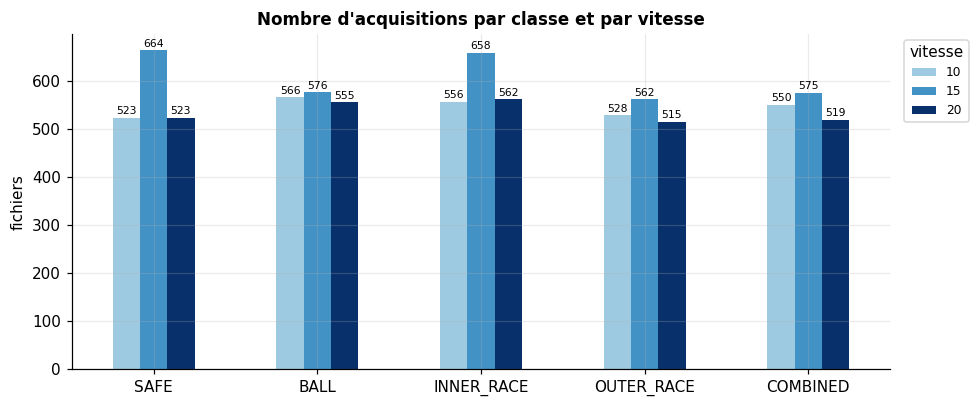

In [3]:
lignes = []
for f in sorted(DATA_DIR.glob("*/*/*.xlsx")):
    if f.name.startswith("~$"):            # fichiers temporaires créés par Excel
        continue
    lignes.append({"classe": f.parent.parent.name,
                   "vitesse": int(f.parent.name.split("_")[-1]),
                   "fichier": f.name,
                   "chemin": str(f)})
meta = pd.DataFrame(lignes)
print(f"{len(meta)} fichiers")

effectifs = pd.crosstab(meta.classe, meta.vitesse).loc[CLASSES]
ax = effectifs.plot.bar(figsize=(9, 3.8), rot=0, color=[COULEURS_VITESSE[str(v)] for v in effectifs.columns])
etiqueter_barres(ax, fmt="%d", taille=7)
ax.set(title="Nombre d'acquisitions par classe et par vitesse", xlabel="", ylabel="fichiers")
ax.legend(title="vitesse", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

**Lecture.** Le jeu est **équilibré** : environ 1 600 à 1 800 acquisitions par classe, réparties à peu près également entre les trois vitesses. Aucune classe ne domine, ce qui simplifie l'évaluation et, on le verra en partie 9, rend possible la standardisation par vitesse.

### 1.2 Découpage train / validation / test, avant tout prétraitement

Toute opération qui « apprend » quelque chose des données (moyenne et écart-type d'une standardisation, choix d'un seuil, entraînement d'un modèle) ne doit voir **que** le jeu d'entraînement. Si le jeu de test influence ces choix, même indirectement, les performances mesurées sont trop optimistes : c'est une **fuite de données**. On découpe donc **dès maintenant**.

| Ensemble | Part | Rôle |
|---|---|---|
| train | 70 % | apprendre les modèles et les normalisations |
| validation | 15 % | régler les choix (seuil de détection) |
| test | 15 % | mesurer les performances finales, une seule fois |

Le découpage est **stratifié** par couple (classe, vitesse) : chaque ensemble contient les mêmes proportions de chaque condition expérimentale.

> ⚠️ **Limite connue.** Chaque couple (classe, vitesse) est une **seule série d'acquisitions consécutives**. Un découpage aléatoire place des acquisitions voisines, presque identiques, dans le train et dans le test. Les scores obtenus sont donc **optimistes** ; on le garde en tête pour toutes les conclusions.

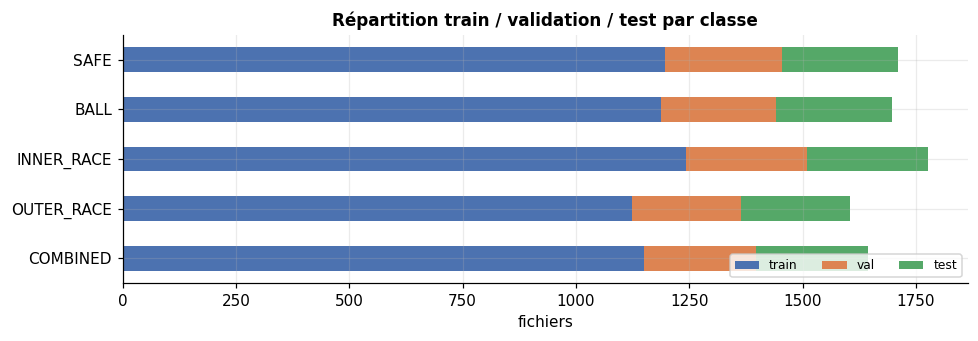

split,train,val,test
classe,,,
SAFE,1197,257,256
BALL,1188,254,255
INNER_RACE,1243,267,266
OUTER_RACE,1124,240,241
COMBINED,1150,247,247


In [4]:
strate = meta.classe + "_" + meta.vitesse.astype(str)
idx_train, idx_reste = train_test_split(meta.index, test_size=0.30, stratify=strate, random_state=SEED)
idx_val, idx_test = train_test_split(idx_reste, test_size=0.50, stratify=strate[idx_reste], random_state=SEED)

meta["split"] = "train"
meta.loc[idx_val, "split"] = "val"
meta.loc[idx_test, "split"] = "test"

repartition = pd.crosstab(meta.classe, meta.split)[["train", "val", "test"]].loc[CLASSES]
ax = repartition.plot.barh(stacked=True, figsize=(9, 3.2), color=["#4c72b0", "#dd8452", "#55a868"])
ax.set(title="Répartition train / validation / test par classe", xlabel="fichiers", ylabel="")
ax.invert_yaxis(); ax.legend(ncol=3, fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
repartition

---
## 2. Lecture des fichiers et premiers signaux

### 2.1 Lire un fichier Excel
Les fichiers exportés par le logiciel National Instruments font planter `pd.read_excel` (feuille de styles non standard). Un `.xlsx` est en réalité une **archive ZIP contenant des fichiers XML** : on lit directement les valeurs dans le XML.

Les fichiers n'ont pas tous le même format (colonne `Time` présente ou non, capteurs supplémentaires, noms accentués). La fonction est donc robuste :
1. les colonnes sont retrouvées **par leur nom**, après normalisation (sans espaces, minuscules, sans accents) ;
2. seuls les **deux accéléromètres communs** à toutes les acquisitions sont gardés ;
3. un fichier est **rejeté avec un message clair** si un capteur manque ou si le signal n'a pas 25 600 points.

La fonction renvoie un tableau numpy de forme `(25600, 2)` : 25 600 instants × 2 capteurs.

In [5]:
NS = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"

def normaliser(nom):
    # " Accélération_Vert " -> "acceleration_vert" : sans espaces autour, minuscules, sans accents
    nom = unicodedata.normalize("NFKD", str(nom).strip().lower())
    return "".join(ch for ch in nom if not unicodedata.combining(ch))

def lire_textes(archive):
    # Les textes (noms de colonnes) peuvent être stockés à part, dans sharedStrings.xml
    textes = []
    if "xl/sharedStrings.xml" in archive.namelist():
        for _, el in iterparse(archive.open("xl/sharedStrings.xml")):
            if el.tag == NS + "si":
                textes.append("".join(t.text or "" for t in el.iter(NS + "t")))
    return textes

def lire_signal(chemin):
    archive = zipfile.ZipFile(chemin)
    textes = lire_textes(archive)
    lignes = []
    for _, el in iterparse(archive.open("xl/worksheets/sheet1.xml")):
        if el.tag == NS + "row":
            ligne = []
            for c in el.findall(NS + "c"):
                v = c.find(NS + "v")
                if c.get("t") == "s":
                    ligne.append(textes[int(v.text)])
                elif c.get("t") == "inlineStr":
                    ligne.append("".join(x.text or "" for x in c.iter(NS + "t")))
                else:
                    ligne.append(float(v.text) if v is not None else np.nan)
            lignes.append(ligne)
            el.clear()                               # libère la mémoire au fil de la lecture

    df = pd.DataFrame(lignes[1:], columns=[normaliser(n) for n in lignes[0]])
    manquants = [c for c in CANAUX if c not in df.columns]
    if manquants:
        raise ValueError(f"capteurs {manquants} absents ; colonnes du fichier : {lignes[0]}")
    if len(df) != N_POINTS:
        raise ValueError(f"{len(df)} points au lieu de {N_POINTS}")
    return df[CANAUX].to_numpy(dtype=np.float32)

### 2.2 Formats de fichiers rencontrés
Un diagnostic de la ligne d'en-tête de chaque fichier a mis en évidence plusieurs formats :

| Colonnes du fichier | Fichiers concernés |
|---|---|
| `acceleration_vertbleu \| acceleration_vert` | 1 697 BALL, 1 626 COMBINED, 1 770 INNER_RACE, 1 OUTER_RACE |
| `Time \| acceleration_vertbleu \| acceleration_vert` | 1 710 SAFE, 1 604 OUTER_RACE |
| `Pression acoustique \| acceleration_vertbleu \| acceleration_vert` | 18 COMBINED |
| `Time \| Accélération_hori_blue \| Accélération_vert \| Accélération_vertbleu \| Pression acoustique` | 6 INNER_RACE |

Une sélection des colonnes **par position** aurait mélangé les capteurs des 6 fichiers à quatre voies sans aucune erreur visible : d'où la sélection **par nom** de `lire_signal`. Ce diagnostic est long (lecture de tous les fichiers) ; il est désactivé par défaut.

In [ ]:
FAIRE_DIAGNOSTIC_ENTETES = False      # passer à True pour refaire le diagnostic (plusieurs minutes)

def lire_entete(chemin):
    archive = zipfile.ZipFile(chemin)
    textes = lire_textes(archive)
    for _, el in iterparse(archive.open("xl/worksheets/sheet1.xml")):
        if el.tag == NS + "row":                  # on s'arrête à la 1re ligne
            entete = []
            for c in el.findall(NS + "c"):
                v = c.find(NS + "v")
                if c.get("t") == "s":
                    entete.append(textes[int(v.text)])
                elif c.get("t") == "inlineStr":
                    entete.append("".join(x.text or "" for x in c.iter(NS + "t")))
                else:
                    entete.append("<nombre>")
            return " | ".join(entete)
    return "<feuille vide>"

if FAIRE_DIAGNOSTIC_ENTETES:
    meta["entete"] = Parallel(n_jobs=-1)(delayed(lire_entete)(c) for c in meta.chemin)
    display(pd.crosstab(meta.entete, meta.classe))

### 2.3 Un signal par classe
On compare un fichier **du jeu d'entraînement** par classe, **à la même vitesse** : sinon, on verrait l'effet de la vitesse et non celui du défaut.

**Signal temporel.** Un roulement défectueux produit des **chocs** (pics brefs) à chaque passage d'un élément roulant sur le défaut. On affiche 100 ms, avec la même échelle verticale pour toutes les classes d'un même capteur.

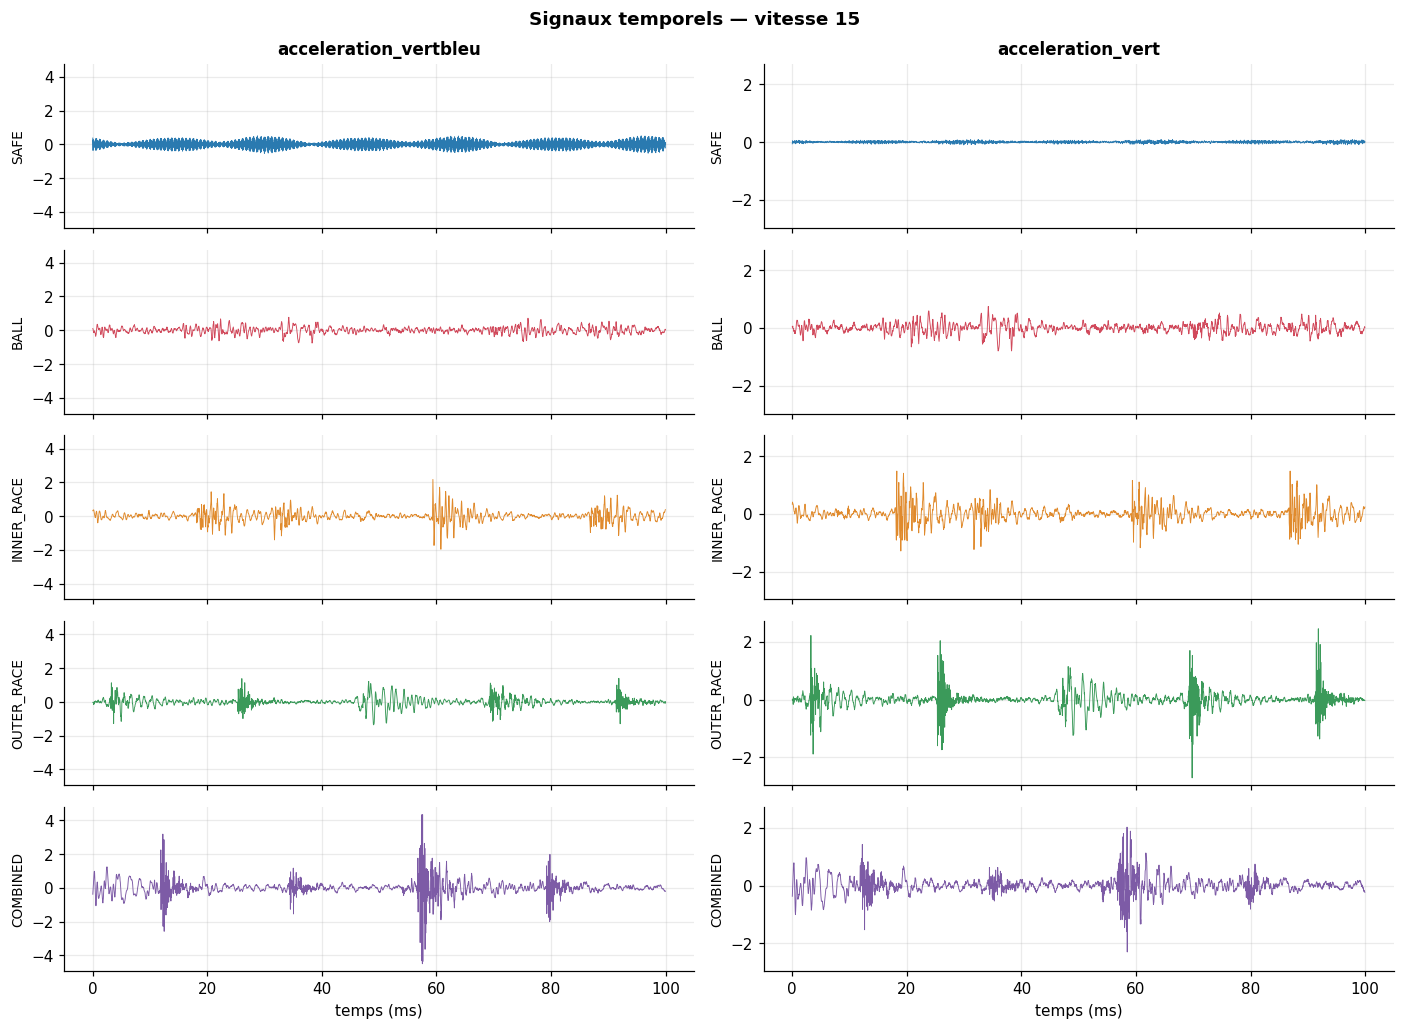

In [6]:
VITESSE_EXEMPLE = 15
exemples = {}
for c in CLASSES:
    choix = meta[(meta.split == "train") & (meta.classe == c) & (meta.vitesse == VITESSE_EXEMPLE)]
    exemples[c] = lire_signal(choix.chemin.iloc[0])

t_ms = np.arange(2560) / FS * 1000                    # 100 premières millisecondes
fig, ax = plt.subplots(len(CLASSES), 2, figsize=(13, 9.5), sharex=True, sharey="col")
for i, c in enumerate(CLASSES):
    for j, canal in enumerate(CANAUX):
        s = exemples[c][:2560, j]
        ax[i, j].plot(t_ms, s - s.mean(), lw=0.6, color=COULEURS[c])
        ax[i, j].set_ylabel(c, fontsize=9)
for j, canal in enumerate(CANAUX):
    ax[0, j].set_title(canal)
    ax[-1, j].set_xlabel("temps (ms)")
fig.suptitle(f"Signaux temporels — vitesse {VITESSE_EXEMPLE}", fontweight="bold")
plt.tight_layout(); plt.show()

**Lecture.** SAFE a une vibration régulière de faible amplitude. Les défauts font apparaître des **impulsions répétées**, très nettes pour INNER_RACE, OUTER_RACE et COMBINED. Le capteur `acceleration_vert` est moins sensible : ses amplitudes sont plus faibles, il faudra donc **standardiser chaque descripteur** avant tout modèle.

**Densité spectrale de puissance (DSP).** Elle indique comment l'énergie se répartit entre les fréquences. On utilise la méthode de **Welch** : le signal est découpé en interne en segments dont on moyenne les spectres, ce qui donne un résultat moins bruité. La fréquence maximale visible est $f_s/2 = 12{,}8$ kHz (fréquence de Nyquist). Les pointillés marquent 3, 6 et 12 kHz.

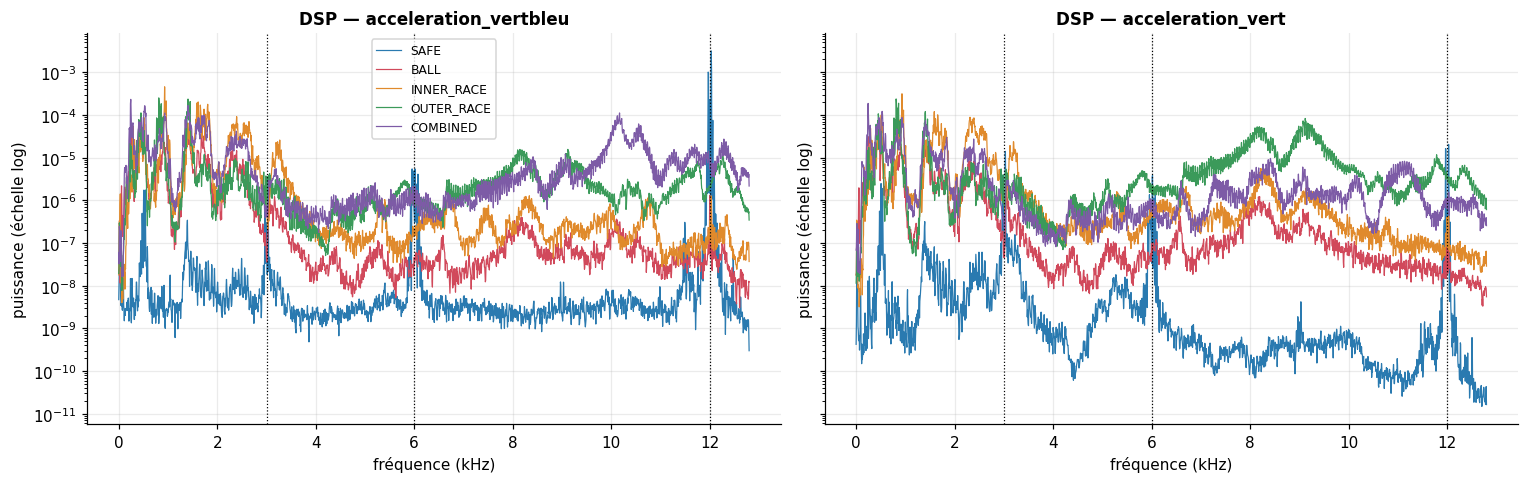

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for j, canal in enumerate(CANAUX):
    for c in CLASSES:
        s = exemples[c][:, j]
        f, P = signal.welch(s - s.mean(), fs=FS, nperseg=4096)
        ax[j].semilogy(f / 1000, P, lw=0.8, color=COULEURS[c], label=c)
    for raie in (3, 6, 12):
        ax[j].axvline(raie, color="k", ls=":", lw=0.8)
    ax[j].set(title=f"DSP — {canal}", xlabel="fréquence (kHz)", ylabel="puissance (échelle log)")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.**
- Les défauts augmentent l'énergie sur une large plage de fréquences : les chocs excitent les résonances de la structure.
- Le spectre de SAFE présente des **raies marquées vers 3, 6 et 12 kHz**. Ces fréquences, multiples de 3 kHz, ne correspondent à aucun phénomène mécanique attendu : elles viennent probablement de l'instrumentation. Si elles sont propres aux acquisitions saines, un modèle peut apprendre à reconnaître la session d'acquisition plutôt que l'absence de défaut. On le vérifiera avec l'analyse d'interprétabilité (partie 6.6).

---
## 3. Construction de la base de descripteurs

Un autoencodeur dense prend en entrée un **vecteur de taille fixe**. On résume donc chaque signal de 25 600 × 2 points par un vecteur de **descripteurs** : la base devient un tableau avec **une ligne par signal**.

### 3.1 Les descripteurs, calculés pour chacun des 2 capteurs

**Descripteurs temporels** (après avoir retiré la moyenne du signal) :

| Descripteur | Formule | Interprétation |
|---|---|---|
| RMS | $\sqrt{\frac{1}{N}\sum x_i^2}$ | énergie vibratoire globale |
| Kurtosis | $\frac{\frac{1}{N}\sum x_i^4}{\text{RMS}^4}$ | ≈ 3 pour un bruit gaussien, **> 3 en présence de chocs** |
| Facteur de crête | $\frac{\max\lvert x\rvert}{\text{RMS}}$ | importance des pics par rapport au niveau moyen |
| Skewness | $\frac{\frac{1}{N}\sum x_i^3}{\text{RMS}^3}$ | asymétrie du signal |
| Crête-à-crête | $\max x - \min x$ | amplitude totale |

**Descripteurs fréquentiels.** La DSP de Welch (segments de 512 points) a une résolution de $25\,600/512 = 50$ Hz. Les 256 raies de 50 Hz à 12,8 kHz sont regroupées en **8 bandes de 1,6 kHz**, et on garde le $\log_{10}$ de l'énergie de chaque bande. Le log est nécessaire car ces énergies varient sur plusieurs ordres de grandeur.

→ 5 + 8 = 13 descripteurs par capteur, soit **26 colonnes**. On garde aussi le **spectre complet** (log-DSP, 256 raies × 2 capteurs = 512 valeurs), comme seconde représentation plus riche.

In [8]:
SUFFIXE = {"acceleration_vertbleu": "vb", "acceleration_vert": "v"}
N_BANDES = 8

def extraire(chemin):
    sig = lire_signal(chemin)
    desc, spectre = {}, []
    for j, canal in enumerate(CANAUX):
        x = sig[:, j] - sig[:, j].mean()
        rms = np.sqrt(np.mean(x ** 2))
        s = SUFFIXE[canal]
        desc[f"rms_{s}"] = rms
        desc[f"kurtosis_{s}"] = stats.kurtosis(x, fisher=False)
        desc[f"crete_{s}"] = np.max(np.abs(x)) / rms
        desc[f"skew_{s}"] = stats.skew(x)
        desc[f"pkpk_{s}"] = x.max() - x.min()

        f, P = signal.welch(x, fs=FS, nperseg=512)      # 257 fréquences de 0 à 12,8 kHz
        for b, bande in enumerate(np.array_split(P[1:], N_BANDES)):
            desc[f"bande{b + 1}_{s}"] = np.log10(bande.sum())
        spectre.append(np.log10(P[1:]))                 # 256 valeurs (la composante continue est exclue)
    return desc, np.concatenate(spectre)

### 3.2 Visualiser les bandes de fréquence
À gauche, le spectre d'un signal sain et d'un signal défectueux, avec les 8 bandes en arrière-plan. À droite, les 8 descripteurs de bande obtenus pour chaque classe : c'est le **profil spectral** que verra le modèle.

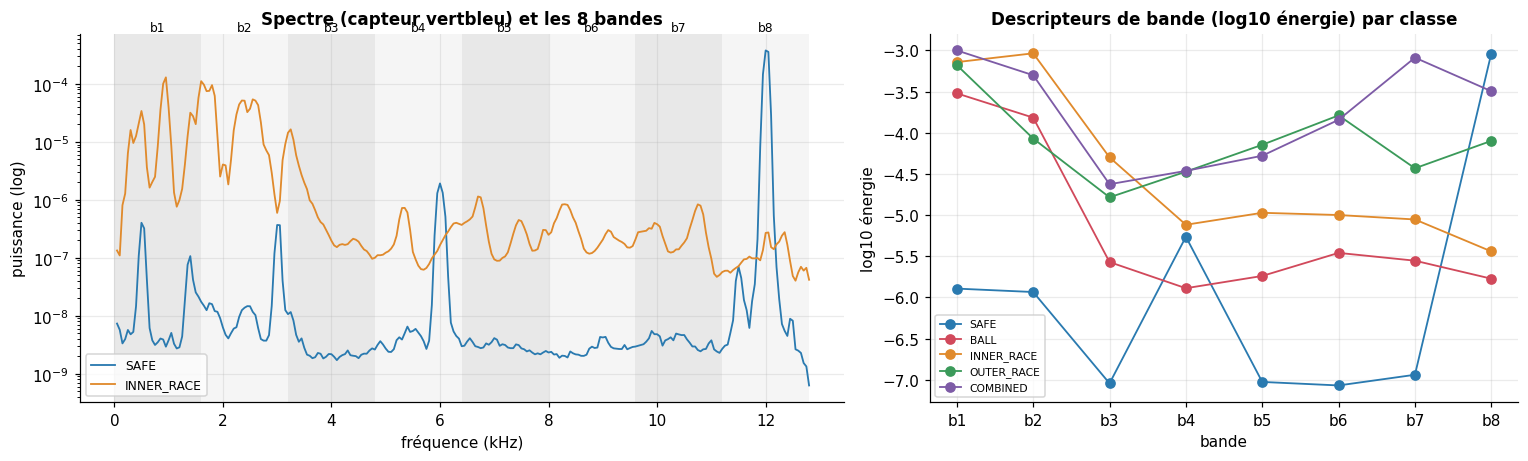

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
for c in ["SAFE", "INNER_RACE"]:
    s = exemples[c][:, 0]
    f, P = signal.welch(s - s.mean(), fs=FS, nperseg=512)
    ax[0].semilogy(f[1:] / 1000, P[1:], color=COULEURS[c], label=c, lw=1.2)
for b in range(N_BANDES):
    ax[0].axvspan(b * 1.6, (b + 1) * 1.6, color="grey", alpha=0.08 if b % 2 else 0.18, lw=0)
    ax[0].text(b * 1.6 + 0.8, ax[0].get_ylim()[1], f"b{b + 1}", ha="center", va="bottom", fontsize=8)
ax[0].set(title="Spectre (capteur vertbleu) et les 8 bandes", xlabel="fréquence (kHz)", ylabel="puissance (log)")
ax[0].legend(fontsize=8)

energies = {}                                        # mêmes calculs que dans extraire()
for c in CLASSES:
    s = exemples[c][:, 0]
    f, P = signal.welch(s - s.mean(), fs=FS, nperseg=512)
    energies[c] = [np.log10(bande.sum()) for bande in np.array_split(P[1:], N_BANDES)]
profil = pd.DataFrame(energies, index=[f"b{b + 1}" for b in range(N_BANDES)])
profil.plot(ax=ax[1], marker="o", color=[COULEURS[c] for c in CLASSES], lw=1.2)
ax[1].set(title="Descripteurs de bande (log10 énergie) par classe", xlabel="bande", ylabel="log10 énergie")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 3.3 Calcul sur tous les fichiers (une seule fois)
La lecture des ~8 400 fichiers Excel prend du temps. Elle se fait **en parallèle** sur tous les cœurs du processeur (`joblib`), puis le résultat est **sauvegardé** dans `bd_v1.pkl` : aux exécutions suivantes, la cellule le recharge simplement. Un fichier illisible est écarté et affiché, sans arrêter le calcul.

In [10]:
FICHIER_BD = Path("bd_v1.pkl")

if FICHIER_BD.exists():
    bd, SPECTRES = pd.read_pickle(FICHIER_BD)
    print("Base rechargée depuis", FICHIER_BD)
else:
    def extraire_sans_planter(chemin):
        try:
            return extraire(chemin)
        except Exception as e:
            return f"ERREUR : {e}"

    resultats = Parallel(n_jobs=-1, verbose=5)(delayed(extraire_sans_planter)(c) for c in meta.chemin)
    ok = np.array([not isinstance(r, str) for r in resultats])
    for chemin, r in zip(meta.chemin[~ok], np.array(resultats, dtype=object)[~ok]):
        print("Écarté :", chemin, "->", r)
    meta_ok = meta[ok].reset_index(drop=True)
    resultats = [r for r in resultats if not isinstance(r, str)]
    bd = pd.concat([meta_ok, pd.DataFrame([r[0] for r in resultats])], axis=1)
    SPECTRES = np.stack([r[1] for r in resultats])
    pd.to_pickle((bd, SPECTRES), FICHIER_BD)
    print(f"Base calculée ({len(bd)} fichiers) et sauvegardée dans", FICHIER_BD)

FEATURES = [c for c in bd.columns if c not in META_COLS]       # les 26 descripteurs
print(f"{len(bd)} signaux × {len(FEATURES)} descripteurs ; spectres : {SPECTRES.shape}")
bd[["classe", "vitesse", "fichier", "split"] + FEATURES[:6]].head()

Base rechargée depuis bd_v1.pkl
8431 signaux × 26 descripteurs ; spectres : (8431, 512)


,classe,vitesse,fichier,split,rms_vb,kurtosis_vb,crete_vb,skew_vb,pkpk_vb,bande1_vb
0,BALL,10,ball_98_1.xlsx,train,0.080564,6.498371,6.332830,0.024661,1.012888,-3.984047
1,BALL,10,ball_98_10.xlsx,val,0.078880,8.539516,7.314891,-0.120976,1.147480,-4.015842
2,BALL,10,ball_98_100.xlsx,train,0.084471,7.748799,7.107885,0.119927,1.144371,-3.936628
3,BALL,10,ball_98_101.xlsx,train,0.083150,8.009208,9.463366,-0.059845,1.511923,-3.946992
4,BALL,10,ball_98_102.xlsx,test,0.045639,3.783657,6.620051,-0.021475,0.568496,-4.560833


---
## 4. Analyse exploratoire de la base (jeu d'entraînement uniquement)

On explore **uniquement le train** : les conclusions de cette analyse orientent les choix de modélisation, elles ne doivent donc pas s'appuyer sur le test.

### 4.1 Profil moyen de chaque classe
Pour chaque descripteur, on calcule la moyenne de chaque classe, puis on la centre-réduit **entre les classes**. Une case rouge : la classe a une valeur nettement au-dessus des autres pour ce descripteur ; une case bleue : nettement en dessous. Ce graphique résume en une image ce qui distingue chaque état.

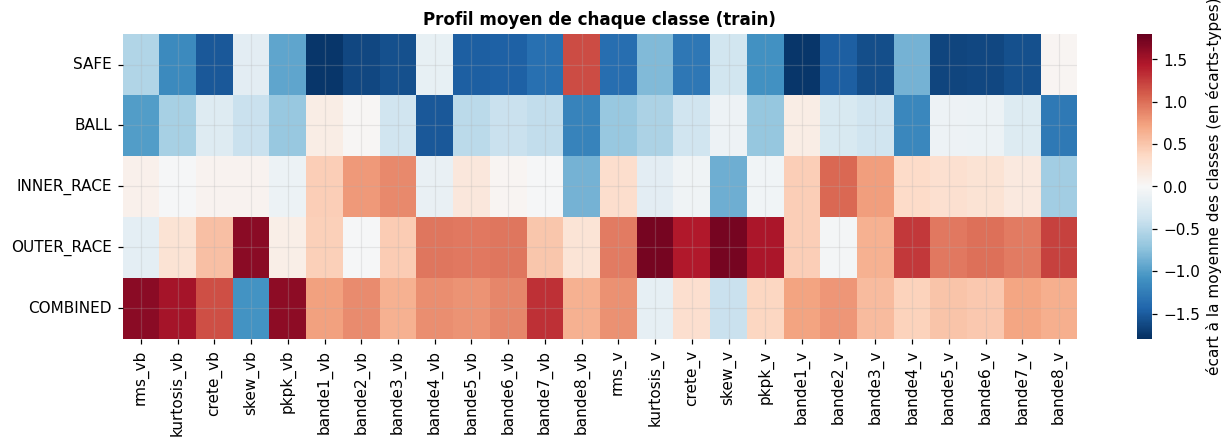

In [11]:
train = bd[bd.split == "train"]
moyennes = train.groupby("classe")[FEATURES].mean().loc[CLASSES]
profil_z = (moyennes - moyennes.mean()) / moyennes.std()

plt.figure(figsize=(14, 3.6))
sns.heatmap(profil_z, cmap="RdBu_r", center=0, vmin=-1.8, vmax=1.8, xticklabels=True,
            cbar_kws={"label": "écart à la moyenne des classes (en écarts-types)"})
plt.title("Profil moyen de chaque classe (train)"); plt.ylabel(""); plt.show()

**Lecture.** SAFE se distingue par une **kurtosis et un facteur de crête faibles** (pas de chocs) et des énergies de bande faibles, sauf la bande 8 (11,2–12,8 kHz), qui contient la raie parasite à 12 kHz. COMBINED a les énergies les plus élevées. OUTER_RACE a une kurtosis particulièrement élevée sur le capteur `vert`.

### 4.2 Distribution des descripteurs par classe
Un bon descripteur pour la **détection** sépare SAFE des défauts ; un bon descripteur pour le **clustering** sépare aussi les défauts entre eux.

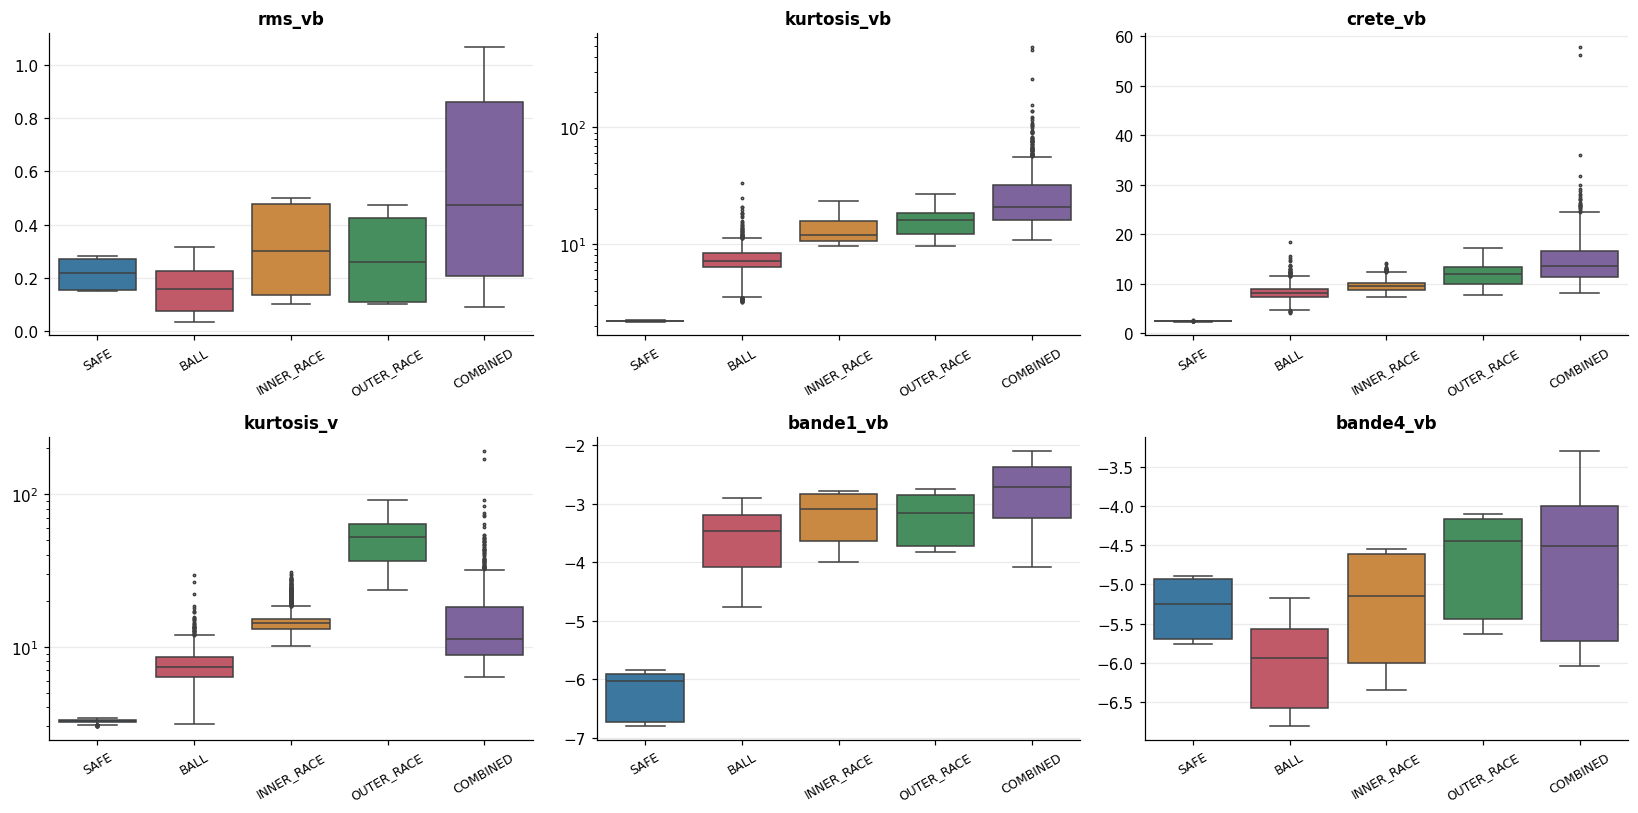

In [12]:
a_tracer = ["rms_vb", "kurtosis_vb", "crete_vb", "kurtosis_v", "bande1_vb", "bande4_vb"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
for a, col in zip(ax.flat, a_tracer):
    sns.boxplot(data=train, x="classe", y=col, order=CLASSES, palette=COULEURS, hue="classe",
                ax=a, fliersize=1.5, legend=False)
    a.set(title=col, xlabel="", ylabel="")
    a.tick_params(axis="x", rotation=30, labelsize=8)
    if col.startswith("kurtosis"):
        a.set_yscale("log")
plt.tight_layout(); plt.show()

**Lecture.**
- **La kurtosis sépare parfaitement SAFE des défauts** (≈ 2–3 contre 7 à plus de 30) : c'est la signature des chocs.
- **Le RMS est trompeur** : BALL a un RMS plus faible que SAFE. Un défaut se manifeste d'abord par des pics, pas par plus d'énergie globale.
- Les défauts se **chevauchent** sur la plupart des descripteurs : les distinguer entre eux sera plus difficile que de les détecter.

### 4.3 Effet de la vitesse : un facteur de confusion
Si la vitesse modifie fortement les descripteurs, le clustering risque de regrouper les signaux **par vitesse** plutôt que **par défaut**. Chaque courbe suit la médiane d'une classe quand la vitesse augmente.

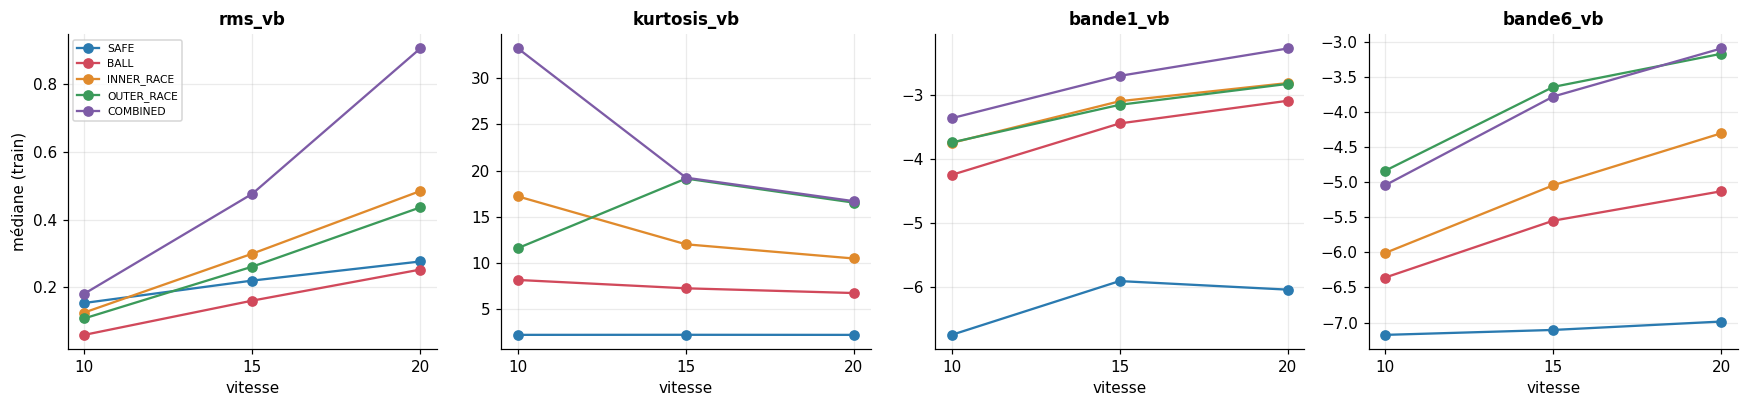

In [13]:
a_suivre = ["rms_vb", "kurtosis_vb", "bande1_vb", "bande6_vb"]
medianes = train.groupby(["classe", "vitesse"])[a_suivre].median()

fig, ax = plt.subplots(1, len(a_suivre), figsize=(16, 3.8))
for a, col in zip(ax, a_suivre):
    for c in CLASSES:
        a.plot(medianes.loc[c].index, medianes.loc[c][col], "o-", color=COULEURS[c], label=c)
    a.set(title=col, xlabel="vitesse", xticks=[10, 15, 20])
ax[0].set_ylabel("médiane (train)")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Lecture.** Les descripteurs d'énergie augmentent fortement avec la vitesse, et **pas de la même façon pour toutes les classes** : le RMS de COMBINED est multiplié par 5 entre les vitesses 10 et 20, celui de SAFE beaucoup moins. Un COMBINED lent peut donc ressembler davantage à un SAFE rapide qu'à un COMBINED rapide. La kurtosis, rapport sans unité, dépend moins de la vitesse.

### 4.4 Mesurer la confusion : la part de variance expliquée $\eta^2$
Pour chaque descripteur $x$ et un regroupement $g$ (vitesse ou classe) :

$$\eta^2_g = 1 - \frac{\sum_i \left(x_i - \bar{x}_{g(i)}\right)^2}{\sum_i \left(x_i - \bar{x}\right)^2}$$

où $\bar{x}_{g(i)}$ est la moyenne du groupe de l'observation $i$. $\eta^2 = 1$ : le regroupement explique toute la variation du descripteur ; $\eta^2 = 0$ : il n'en explique rien. Un bon descripteur a un $\eta^2$ **classe élevé** et un $\eta^2$ **vitesse faible**.

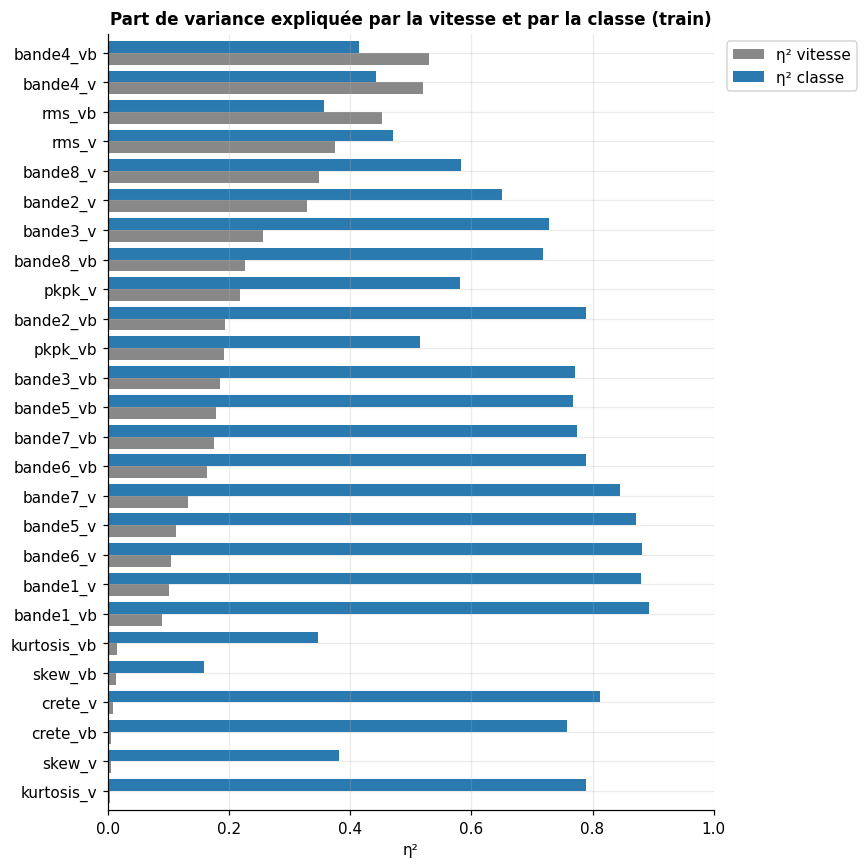

η² vitesse    0.189
η² classe     0.653
dtype: float64

In [14]:
eta_avant = pd.DataFrame({
    "η² vitesse": [eta2(train[f], train.vitesse) for f in FEATURES],
    "η² classe":  [eta2(train[f], train.classe) for f in FEATURES],
}, index=FEATURES).sort_values("η² vitesse")

ax = eta_avant.plot.barh(figsize=(8, 8), color=["#888888", "#2a7ab0"], width=0.8)
ax.set(title="Part de variance expliquée par la vitesse et par la classe (train)", xlim=(0, 1), xlabel="η²")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()
eta_avant.mean().round(3)

**Lecture.** En moyenne, la vitesse explique environ un cinquième de la variance des descripteurs : c'est loin d'être négligeable. Certains descripteurs (bandes de fréquence, facteur de crête) sont plus influencés par la vitesse que d'autres. Ce constat motive les stratégies des parties 8 et 9.

### 4.5 Corrélations entre descripteurs
Des descripteurs très corrélés portent la même information. Ce n'est pas bloquant pour un autoencodeur, dont le rôle est justement de compresser cette redondance. On n'affiche que la moitié de la matrice (elle est symétrique).

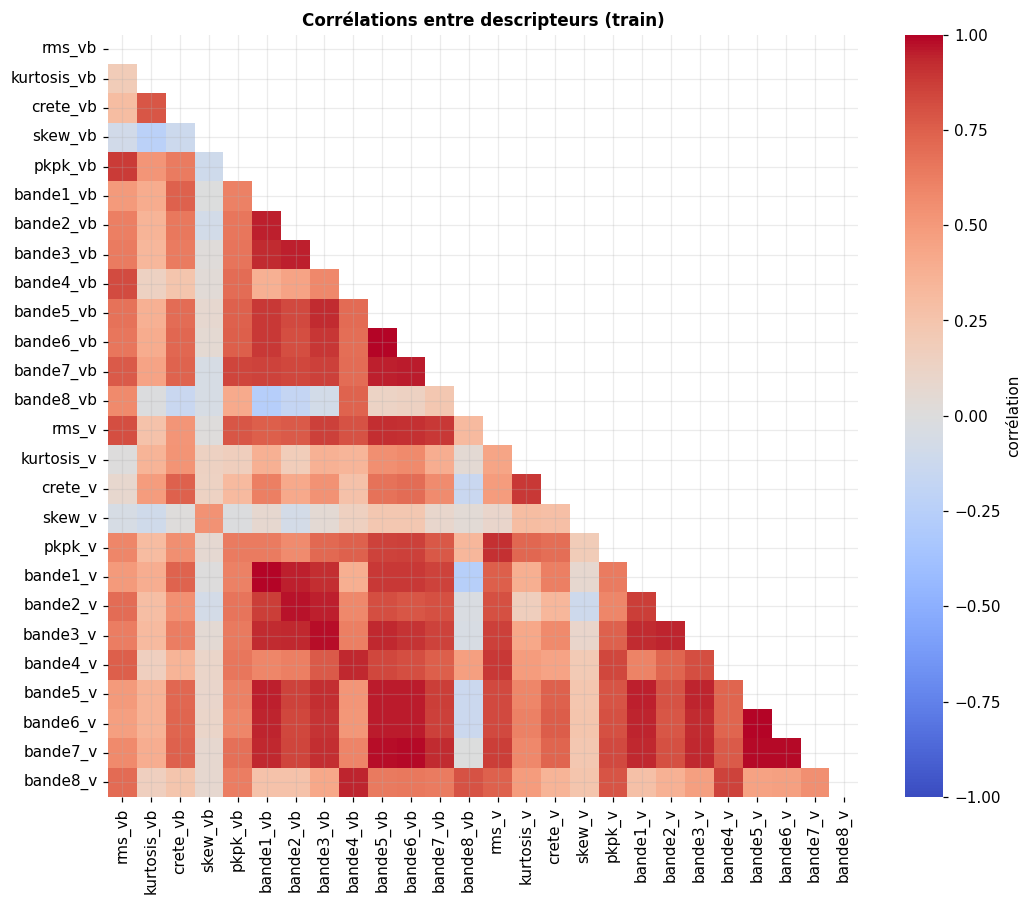

In [15]:
corr = train[FEATURES].corr()
masque = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=masque, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True,
            cbar_kws={"label": "corrélation"})
plt.title("Corrélations entre descripteurs (train)"); plt.show()

**Lecture.** Les descripteurs d'énergie (RMS, crête-à-crête, bandes) sont fortement corrélés entre eux, et chaque descripteur est corrélé à son équivalent sur l'autre capteur. Il y a donc beaucoup de **redondance** : 26 colonnes, mais beaucoup moins de « directions » d'information indépendantes, comme le confirme l'ACP ci-dessous.

### 4.6 Vue d'ensemble en 2D : l'ACP
L'**analyse en composantes principales** (ACP) cherche les directions de plus grande variance. Le graphique de gauche montre combien de variance chaque composante explique ; les deux autres projettent les données sur les 2 premières composantes, colorées par classe puis par vitesse.

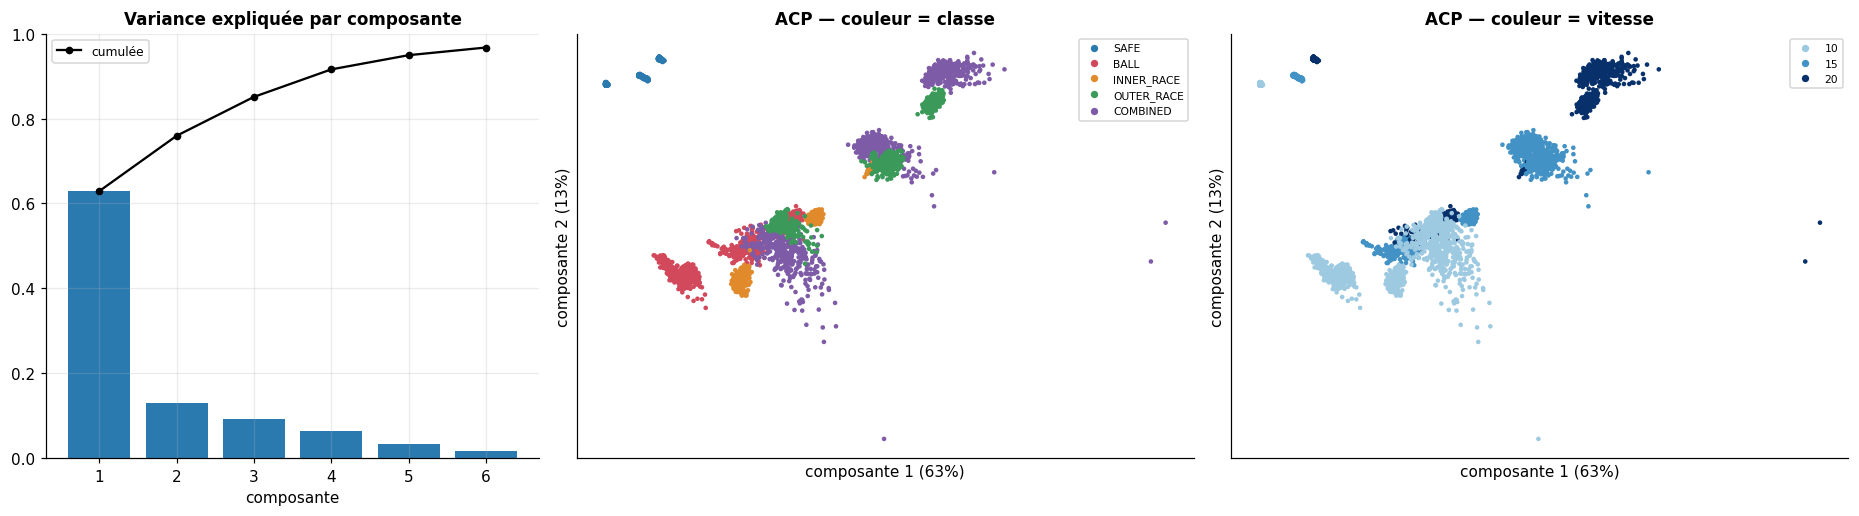

In [16]:
X_vis = StandardScaler().fit_transform(train[FEATURES])
acp = PCA(n_components=6, random_state=SEED).fit(X_vis)
Z_vis = acp.transform(X_vis)
var = acp.explained_variance_ratio_

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [0.8, 1, 1]})
ax[0].bar(range(1, 7), var, color="#2a7ab0")
ax[0].plot(range(1, 7), var.cumsum(), "ko-", ms=4, label="cumulée")
ax[0].set(title="Variance expliquée par composante", xlabel="composante", ylim=(0, 1))
ax[0].legend(fontsize=8)
tracer_tsne(ax[1], Z_vis[:, :2], train.classe, "ACP — couleur = classe", COULEURS, CLASSES)
tracer_tsne(ax[2], Z_vis[:, :2], train.vitesse.astype(str), "ACP — couleur = vitesse", COULEURS_VITESSE, ["10", "15", "20"])
for a in ax[1:]:
    a.set(xlabel=f"composante 1 ({var[0]:.0%})", ylabel=f"composante 2 ({var[1]:.0%})")
plt.tight_layout(); plt.show()

**Lecture.** Les 2 premières composantes résument déjà une grande part de la variance. SAFE est bien isolé. Le graphique coloré par vitesse montre que la vitesse **structure aussi le nuage** : à l'intérieur d'une même classe, les points s'étalent selon la vitesse.

### 4.7 Synthèse de l'analyse exploratoire
1. **SAFE se distingue facilement** (kurtosis, facteur de crête) : la détection devrait être facile.
2. **Les défauts se chevauchent** : le clustering sera plus difficile.
3. **La vitesse est un facteur de confusion** ($\eta^2$ moyen ≈ 0,2), avec un effet multiplicatif qui dépend de la classe.
4. **Points de vigilance** : raies parasites à 3, 6 et 12 kHz dans SAFE ; séries d'acquisitions consécutives qui rendent les scores optimistes.

---
## 5. Les autoencodeurs

### 5.1 Idée
Un **autoencodeur** (AE) est un réseau de neurones entraîné à **reproduire son entrée** : on lui donne $x$, il doit ressortir $\hat{x} \approx x$.

```
  entrée x          encodeur          code z          décodeur          sortie x̂
 (26 valeurs)  →  26 → 16 → 6   →   (6 valeurs)   →   6 → 16 → 26   →  (26 valeurs)
                                    « goulot »
```

L'intérêt vient du **goulot d'étranglement** : la couche du milieu est plus petite que l'entrée. Pour reconstruire $x$ à partir de seulement 6 nombres, le réseau doit apprendre une **représentation compressée** qui garde l'essentiel de l'information et rejette le bruit.

- **Encodeur** $z = f(x)$ : compresse l'entrée vers l'espace latent.
- **Décodeur** $\hat{x} = g(z)$ : reconstruit l'entrée à partir du code.
- **Espace latent** : l'ensemble des codes $z$.

### 5.2 Apprentissage
On minimise l'**erreur de reconstruction**, ici l'erreur quadratique moyenne (MSE) :

$$\mathcal{L}(x, \hat{x}) = \frac{1}{d}\sum_{k=1}^{d} (x_k - \hat{x}_k)^2$$

par descente de gradient (rétropropagation), comme pour un réseau de régression, sauf que **la cible est l'entrée elle-même**. C'est un apprentissage **non supervisé** : aucune étiquette n'est utilisée. Avec scikit-learn, c'est littéralement `MLPRegressor(...).fit(X, X)`.

### 5.3 Deux usages pour notre projet

| Usage | Ce qu'on exploite | Idée |
|---|---|---|
| **Détection d'anomalie** | l'erreur de reconstruction | entraîné **seulement sur des signaux sains**, l'AE reconstruit bien ce qui ressemble à du sain et **mal ce qui est anormal** : erreur élevée = anomalie |
| **Clustering** | le code latent $z$ | $z$ est une représentation compacte et débruitée ; des signaux similaires ont des codes proches : on applique k-means sur $z$ |

### 5.4 Lien avec l'ACP
Un AE **linéaire** (sans fonction d'activation) entraîné avec une perte MSE apprend le même sous-espace que l'**ACP**. Les fonctions d'activation non linéaires (ici `tanh`) permettent à l'AE de capturer des structures **non linéaires**. L'ACP est donc la **baseline naturelle** : si l'AE ne fait pas mieux, sa complexité n'est pas justifiée.

### 5.5 Outils
- `creer_ae` construit l'autoencodeur. `early_stopping=True` garde 10 % du train pour surveiller l'apprentissage et l'arrête quand il ne progresse plus (protection contre le sur-apprentissage).
- `erreur_reconstruction` calcule l'erreur MSE **par signal** (une valeur par ligne).
- `encoder` calcule le code latent $z$ en appliquant seulement la moitié « encodeur » du réseau.

In [17]:
def creer_ae(couches=(16, 6, 16)):
    # couches = tailles des couches cachées ; celle du milieu est le goulot (espace latent)
    return MLPRegressor(hidden_layer_sizes=couches, activation="tanh", learning_rate_init=1e-3,
                        max_iter=1000, early_stopping=True, n_iter_no_change=30, random_state=SEED)

def erreur_reconstruction(ae, X):
    return np.mean((X - ae.predict(X)) ** 2, axis=1)

def encoder(ae, X):
    # ae.coefs_[k] et ae.intercepts_[k] : poids et biais de la couche k.
    # L'encodeur = les couches jusqu'au goulot (inclus).
    n_couches_encodeur = len(ae.hidden_layer_sizes) // 2 + 1
    h = X
    for W, b in zip(ae.coefs_[:n_couches_encodeur], ae.intercepts_[:n_couches_encodeur]):
        h = np.tanh(h @ W + b)
    return h

---
## 6. Détection d'anomalie

### 6.1 Stratégie
1. **Entraîner** uniquement sur les signaux **SAFE du train** : le modèle apprend ce qu'est un fonctionnement normal. Pas besoin d'exemples de défauts, ce qui est l'intérêt de l'approche en industrie, où les défauts sont rares.
2. **Score d'anomalie** = erreur de reconstruction (ou score équivalent pour les autres modèles).
3. **Seuil** = 99ᵉ percentile des scores des **SAFE de validation** : on accepte environ 1 % de fausses alarmes sur des roulements sains.
4. **Évaluation sur le test** (toutes classes) : un signal est une anomalie si son score dépasse le seuil.

**Métriques.**
- **AUROC** : probabilité qu'un signal défectueux tiré au hasard ait un score plus élevé qu'un signal sain tiré au hasard. Indépendante du seuil ; 0,5 = hasard, 1 = parfait.
- **Rappel** : part des défauts détectés. **Taux de fausses alarmes** : part des SAFE signalés à tort. **Précision** : part des alarmes qui sont de vrais défauts.

**Modèles comparés.**

| Modèle | Rôle | Principe |
|---|---|---|
| Isolation Forest | baseline 1 | un point anormal s'isole en peu de découpages aléatoires |
| ACP | baseline 2 | erreur de reconstruction **linéaire** (6 composantes, comme le goulot de l'AE) |
| Autoencodeur (descripteurs) | modèle principal | erreur de reconstruction non linéaire, sur les 26 descripteurs |
| Autoencodeur (spectre) | variante | même principe sur le spectre complet (512 valeurs) |

### 6.2 Préparation des données
La **standardisation** (moyenne 0, écart-type 1 par colonne) est indispensable pour un réseau de neurones : sans elle, les colonnes de grande amplitude domineraient l'erreur. Le `StandardScaler` est ajusté (**fit**) sur le **train SAFE** uniquement, puis appliqué (**transform**) à tout le reste.

In [18]:
scaler = StandardScaler().fit(bd.loc[(bd.split == "train") & (bd.classe == "SAFE"), FEATURES])
X = scaler.transform(bd[FEATURES])
y = (bd.classe != "SAFE").astype(int).to_numpy()     # 1 = défaut, 0 = sain (sert UNIQUEMENT à évaluer)

m_train_safe = ((bd.split == "train") & (bd.classe == "SAFE")).to_numpy()
m_val_safe   = ((bd.split == "val")   & (bd.classe == "SAFE")).to_numpy()
m_test       = (bd.split == "test").to_numpy()
print(f"entraînement : {m_train_safe.sum()} SAFE | seuil : {m_val_safe.sum()} SAFE | test : {m_test.sum()} signaux")

entraînement : 1197 SAFE | seuil : 257 SAFE | test : 1265 signaux


### 6.3 Entraînement de l'autoencodeur
La **courbe de perte** doit décroître puis se stabiliser. À droite, le score $R^2$ sur les 10 % mis de côté par `early_stopping` : proche de 1, l'AE reconstruit très bien des signaux sains qu'il n'a pas vus.

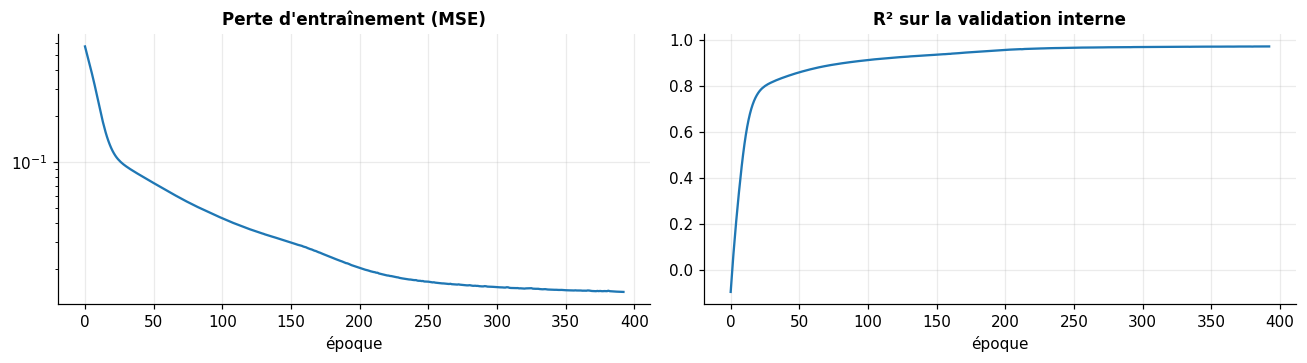

Arrêt après 393 époques


In [19]:
ae = creer_ae((16, 6, 16))
ae.fit(X[m_train_safe], X[m_train_safe])          # entrée = cible : l'AE apprend à reproduire les signaux sains

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(ae.loss_curve_); ax[0].set(title="Perte d'entraînement (MSE)", xlabel="époque", yscale="log")
ax[1].plot(ae.validation_scores_); ax[1].set(title="R² sur la validation interne", xlabel="époque")
plt.tight_layout(); plt.show()
print(f"Arrêt après {ae.n_iter_} époques")

### 6.4 Scores d'anomalie des quatre modèles
Chaque modèle donne un **score** par signal : plus il est grand, plus le signal est suspect. Pour l'Isolation Forest, `score_samples` est grand pour les points normaux : on prend son opposé.

In [20]:
iso = IsolationForest(n_estimators=300, random_state=SEED).fit(X[m_train_safe])
pca_det = PCA(n_components=6, random_state=SEED).fit(X[m_train_safe])

scaler_spec = StandardScaler().fit(SPECTRES[m_train_safe])
X_spec = scaler_spec.transform(SPECTRES)
ae_spec = creer_ae((128, 16, 128))
ae_spec.fit(X_spec[m_train_safe], X_spec[m_train_safe])

scores = {
    "Isolation Forest": -iso.score_samples(X),
    "ACP": np.mean((X - pca_det.inverse_transform(pca_det.transform(X))) ** 2, axis=1),
    "AE (descripteurs)": erreur_reconstruction(ae, X),
    "AE (spectre)": erreur_reconstruction(ae_spec, X_spec),
}

### 6.5 Comparaison des modèles
Pour chaque modèle : seuil fixé sur les SAFE de validation, puis évaluation sur le test. À gauche, les courbes ROC complètes ; au centre, un **zoom** sur les faibles taux de fausses alarmes, la seule zone où les modèles peuvent différer ; à droite, les métriques au seuil choisi.

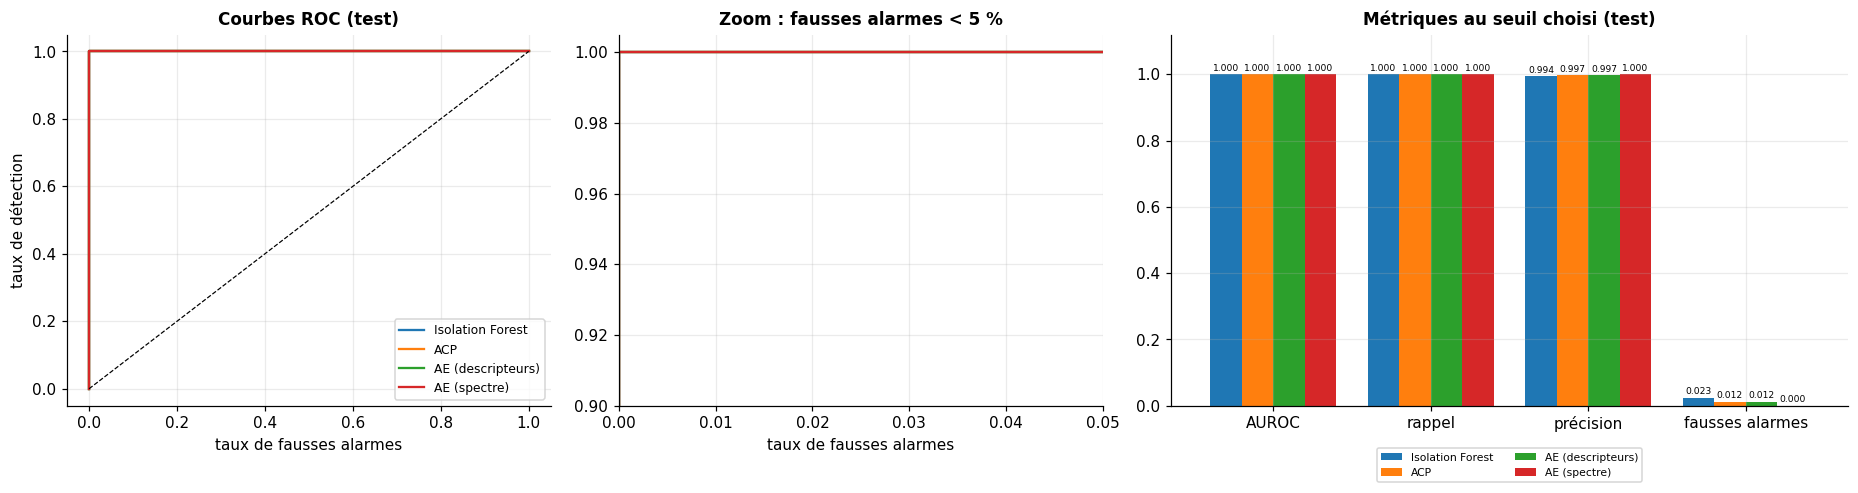

,AUROC,rappel,fausses alarmes,précision,nb fausses alarmes
modèle,,,,,
Isolation Forest,1.0,1.0,0.023,0.994,6
ACP,1.0,1.0,0.012,0.997,3
AE (descripteurs),1.0,1.0,0.012,0.997,3
AE (spectre),1.0,1.0,0.000,1.000,0


In [21]:
lignes_det, seuils = [], {}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for nom, s in scores.items():
    seuils[nom] = np.percentile(s[m_val_safe], 99)            # seuil fixé SANS regarder le test
    pred = (s[m_test] > seuils[nom]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[m_test], pred, labels=[0, 1]).ravel()
    lignes_det.append({"modèle": nom, "AUROC": roc_auc_score(y[m_test], s[m_test]),
                       "rappel": tp / (tp + fn), "fausses alarmes": fp / (fp + tn),
                       "précision": tp / max(tp + fp, 1), "nb fausses alarmes": fp})
    fpr, tpr, _ = roc_curve(y[m_test], s[m_test])
    for a in ax[:2]:
        a.plot(fpr, tpr, label=nom, lw=1.5)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title="Courbes ROC (test)", xlabel="taux de fausses alarmes", ylabel="taux de détection")
ax[1].set(title="Zoom : fausses alarmes < 5 %", xlim=(0, 0.05), ylim=(0.9, 1.005), xlabel="taux de fausses alarmes")
ax[0].legend(fontsize=8)

resultats_det = pd.DataFrame(lignes_det).set_index("modèle")
resultats_det[["AUROC", "rappel", "précision", "fausses alarmes"]].T.plot.bar(ax=ax[2], rot=0, width=0.8)
etiqueter_barres(ax[2], fmt="%.3f", taille=6)
ax[2].set(title="Métriques au seuil choisi (test)", ylim=(0, 1.12))
ax[2].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()
resultats_det.round(3)

**Lecture.** Les quatre modèles atteignent une **AUROC de 1** et détectent **tous les défauts** : sur ces données, séparer sain et défectueux est facile, comme l'annonçait l'analyse exploratoire (kurtosis). Les modèles ne diffèrent que par **quelques fausses alarmes** sur 256 SAFE. Ces écarts de 1 ou 2 signaux ne sont pas significatifs. L'intérêt de l'autoencodeur est ailleurs : son erreur est **interprétable** (6.6), et son espace latent sert au **clustering** (parties 7 à 9).

### 6.6 Où se situent les erreurs de l'autoencodeur ?
**Distribution des scores par classe** (échelle log) : idéalement, SAFE reste sous le seuil et tous les défauts au-dessus. Le tableau de droite donne le **taux d'alarme** par classe et par vitesse : pour SAFE, c'est le taux de fausses alarmes ; pour les défauts, le taux de détection.

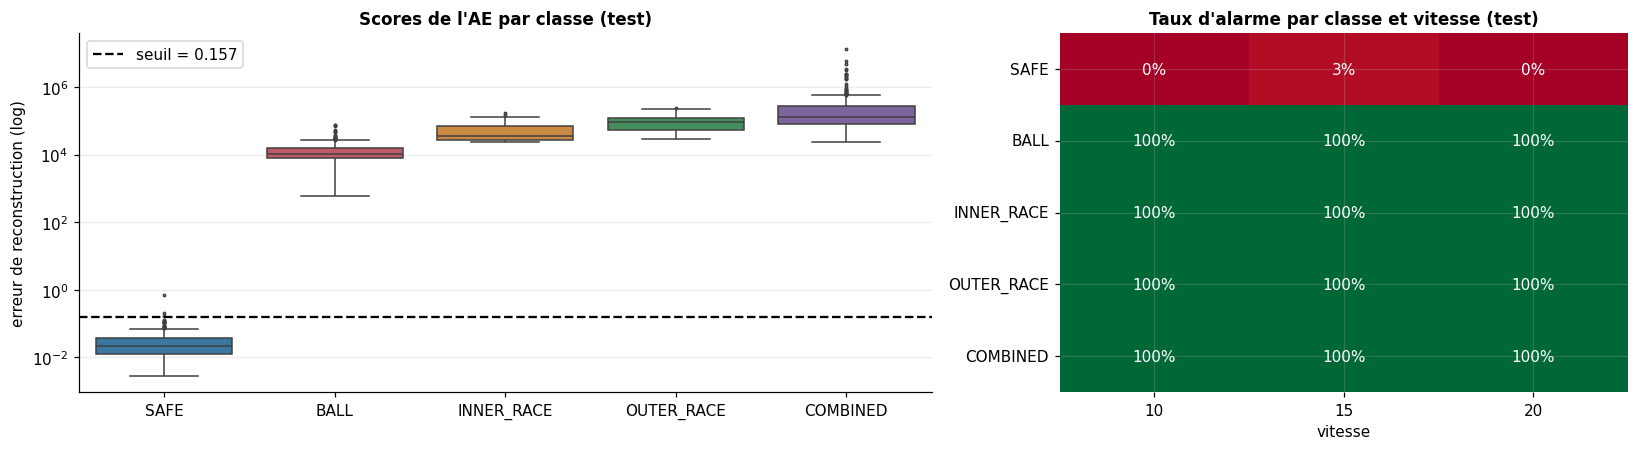

In [22]:
score_ae, seuil_ae = scores["AE (descripteurs)"], seuils["AE (descripteurs)"]
test = bd[m_test].assign(score=score_ae[m_test], alarme=score_ae[m_test] > seuil_ae)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
sns.boxplot(data=test, x="classe", y="score", order=CLASSES, palette=COULEURS, hue="classe",
            ax=ax[0], fliersize=1.5, legend=False)
ax[0].axhline(seuil_ae, color="k", ls="--", label=f"seuil = {seuil_ae:.3f}")
ax[0].set(yscale="log", ylabel="erreur de reconstruction (log)", xlabel="", title="Scores de l'AE par classe (test)")
ax[0].legend()
taux = test.pivot_table(index="classe", columns="vitesse", values="alarme", aggfunc="mean").loc[CLASSES]
sns.heatmap(taux, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, cbar=False, ax=ax[1])
ax[1].set(title="Taux d'alarme par classe et vitesse (test)", ylabel="")
plt.tight_layout(); plt.show()

### 6.7 Interprétabilité : quels descripteurs signalent l'anomalie ?
L'erreur de reconstruction est une **somme sur les descripteurs**. On peut donc la **décomposer** et regarder quels descripteurs l'AE reconstruit mal pour chaque type de défaut. C'est une méthode d'interprétabilité naturelle pour un autoencodeur : elle dit *pourquoi* un signal est jugé anormal.

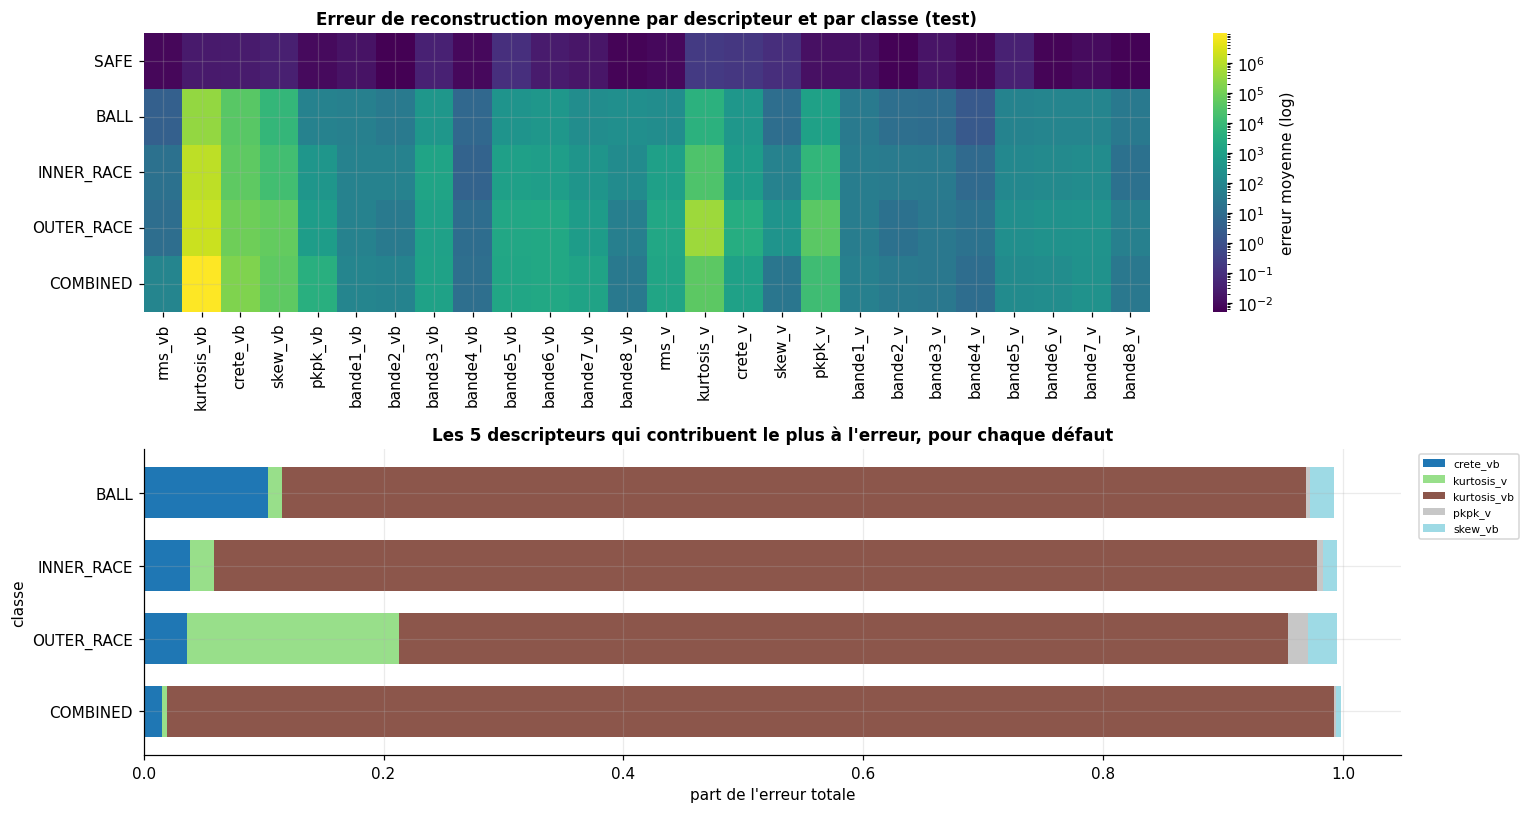

In [23]:
erreur_par_feature = pd.DataFrame((X[m_test] - ae.predict(X[m_test])) ** 2, columns=FEATURES)
erreur_par_feature["classe"] = bd.classe[m_test].to_numpy()
carte = erreur_par_feature.groupby("classe")[FEATURES].mean().loc[CLASSES]

fig, ax = plt.subplots(2, 1, figsize=(14, 7.5), gridspec_kw={"height_ratios": [1, 1.1]})
sns.heatmap(carte, cmap="viridis", norm=LogNorm(), xticklabels=True, ax=ax[0],
            cbar_kws={"label": "erreur moyenne (log)"})
ax[0].set(title="Erreur de reconstruction moyenne par descripteur et par classe (test)", ylabel="")
part = carte.div(carte.sum(axis=1), axis=0).drop(index="SAFE")    # part de l'erreur de chaque descripteur
top = part.T.apply(lambda col: col.nlargest(5)).fillna(0)
top.T.plot.barh(stacked=True, ax=ax[1], colormap="tab20", width=0.7)
ax[1].set(title="Les 5 descripteurs qui contribuent le plus à l'erreur, pour chaque défaut", xlabel="part de l'erreur totale")
ax[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

**Lecture.** En haut, les défauts ont une erreur beaucoup plus forte que SAFE sur presque tous les descripteurs. En bas, on voit **quels descripteurs trahissent chaque défaut**. Deux vérifications à faire :
- **cohérence physique** : la kurtosis et le facteur de crête, signatures des chocs, doivent contribuer fortement ;
- **artefact** : si les bandes 2, 4 et 8 (qui contiennent les raies parasites à 3, 6 et 12 kHz) dominaient, la détection reposerait sur un artefact de mesure.

### 6.8 Analyse des erreurs
Quels signaux de test sont mal classés ? Pour une fausse alarme, on trace les scores de **toute la série d'acquisitions** à laquelle elle appartient, dans l'ordre d'enregistrement (numéro du fichier), tous ensembles confondus. On voit ainsi s'il s'agit d'un point isolé ou d'un **épisode** pendant l'enregistrement.

3 signaux mal classés sur 1265


,classe,vitesse,fichier,score
7819,SAFE,15,safe_1489_639.xlsx,0.162383
7758,SAFE,15,safe_1489_584.xlsx,0.205088
7756,SAFE,15,safe_1489_582.xlsx,0.703473


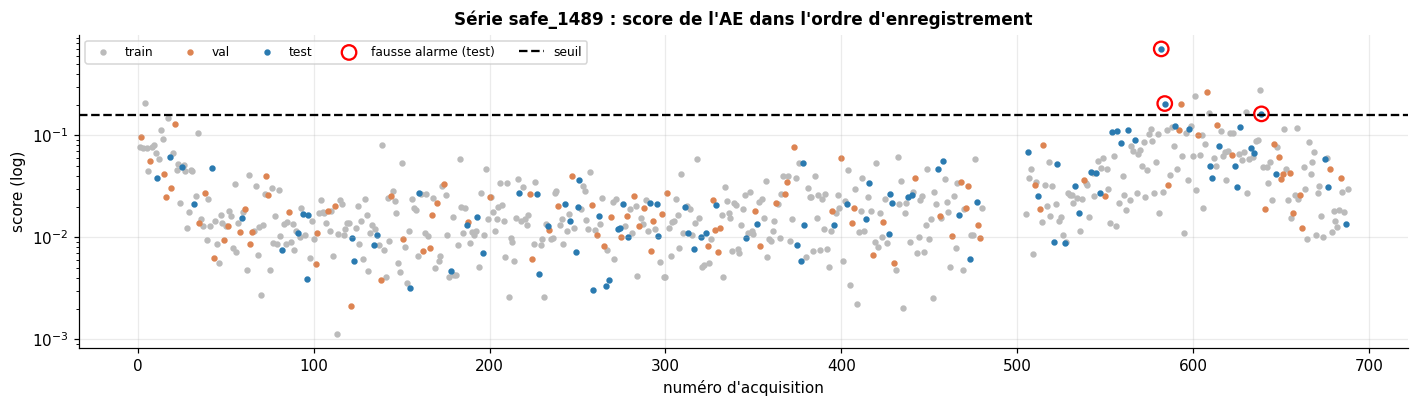

In [24]:
erreurs = test[(test.classe == "SAFE") == test.alarme]          # SAFE en alarme, ou défaut sans alarme
print(f"{len(erreurs)} signaux mal classés sur {len(test)}")
display(erreurs[["classe", "vitesse", "fichier", "score"]].sort_values("score"))

if len(erreurs):
    serie = erreurs.fichier.iloc[0].rsplit("_", 1)[0]               # ex. "safe_1489"
    m_serie = (bd.fichier.str.rsplit("_", n=1).str[0] == serie).to_numpy()
    numeros = bd.fichier[m_serie].str.rsplit("_", n=1).str[1].str.split(".").str[0].astype(int)
    plt.figure(figsize=(13, 3.8))
    for split, couleur in [("train", "#bbbbbb"), ("val", "#dd8452"), ("test", "#2a7ab0")]:
        m = (bd.split[m_serie] == split).to_numpy()
        plt.scatter(numeros[m], score_ae[m_serie][m], s=10, color=couleur, label=split)
    plt.scatter(erreurs.fichier.str.rsplit("_", n=1).str[1].str.split(".").str[0].astype(int), erreurs.score,
                s=90, facecolors="none", edgecolors="red", linewidths=1.5, label="fausse alarme (test)")
    plt.axhline(seuil_ae, color="k", ls="--", label="seuil")
    plt.yscale("log")
    plt.title(f"Série {serie} : score de l'AE dans l'ordre d'enregistrement")
    plt.xlabel("numéro d'acquisition"); plt.ylabel("score (log)"); plt.legend(fontsize=8, ncol=5)
    plt.tight_layout(); plt.show()

**Lecture.** Les fausses alarmes appartiennent toutes à la même série SAFE (vitesse 15) et à des numéros proches. Si les scores voisins (train, validation) sont aussi élevés autour de ces numéros, il s'agit d'un **événement ponctuel pendant l'enregistrement** (choc extérieur, perturbation) plutôt que d'une faiblesse du modèle.

---
## 7. Clustering sans correction : le constat

### 7.1 Stratégie
Objectif : retrouver **les 5 états du roulement sans utiliser les étiquettes**, puis vérifier après coup si les groupes trouvés correspondent aux vraies classes.

1. **Entraîner un nouvel autoencodeur sur tout le train** (toutes classes, sans étiquette). L'AE de la partie 6 ne convient pas : il n'a vu que du SAFE.
2. **Encoder** chaque signal → code latent $z$ (6 valeurs).
3. **Choisir le nombre de groupes $k$** sans étiquettes (silhouette et méthode du coude).
4. **k-means** sur les codes du train, puis affectation des signaux de test.
5. **Évaluer** sur le test avec les étiquettes, uniquement pour juger.

**Baseline** : k-means directement sur les 26 descripteurs standardisés.

**Les métriques.** Notations : une partition $U$ (les vraies classes), une partition $V$ (les clusters), et $n_{ij}$ le nombre de signaux de la classe $i$ placés dans le cluster $j$.

| Métrique | Intuition | Valeurs |
|---|---|---|
| **ARI vs classe** (*Adjusted Rand Index*) | On examine toutes les paires de signaux : les deux partitions sont-elles d'accord pour les mettre ensemble ou les séparer ? Score corrigé du hasard. | 0 = hasard, 1 = parfait |
| **NMI vs classe** (*Normalized Mutual Information*) | Si je connais le cluster d'un signal, quelle part de l'incertitude sur sa classe ai-je levée ? $\mathrm{NMI} = \frac{I(U;V)}{\frac{1}{2}[H(U)+H(V)]}$ | 0 = aucune information, 1 = parfait |
| **Silhouette** | Chaque point est-il plus proche de son cluster ($a$) que du cluster voisin ($b$) ? $s = \frac{b-a}{\max(a,b)}$. **N'utilise pas les étiquettes** : juge la géométrie, pas la justesse. | −1 à 1 |
| **ARI vs vitesse** | Même ARI, mais par rapport à la vitesse : les clusters reproduisent-ils les vitesses ? **Indicateur de biais.** | doit être ≈ 0 |

### 7.2 Entraînement
Cette fois, le `StandardScaler` est ajusté sur **tout le train**.

In [25]:
m_train = (bd.split == "train").to_numpy()

scaler_clu = StandardScaler().fit(bd.loc[m_train, FEATURES])
X_clu = scaler_clu.transform(bd[FEATURES])

ae_clu = creer_ae((16, 6, 16))
ae_clu.fit(X_clu[m_train], X_clu[m_train])
Z = encoder(ae_clu, X_clu)          # codes latents de TOUS les signaux, forme (N, 6)
print(f"AE entraîné en {ae_clu.n_iter_} époques ; espace latent : {Z.shape}")

AE entraîné en 386 époques ; espace latent : (8431, 6)


### 7.3 Choix du nombre de clusters
Deux critères, sans étiquettes :
- **silhouette** : compacité **et** séparation des groupes ; on cherche son **maximum** ;
- **méthode du coude** : l'**inertie** de k-means (somme des distances au carré entre chaque point et le centre de son cluster) diminue toujours quand $k$ augmente ; on cherche le $k$ après lequel elle ne baisse presque plus.

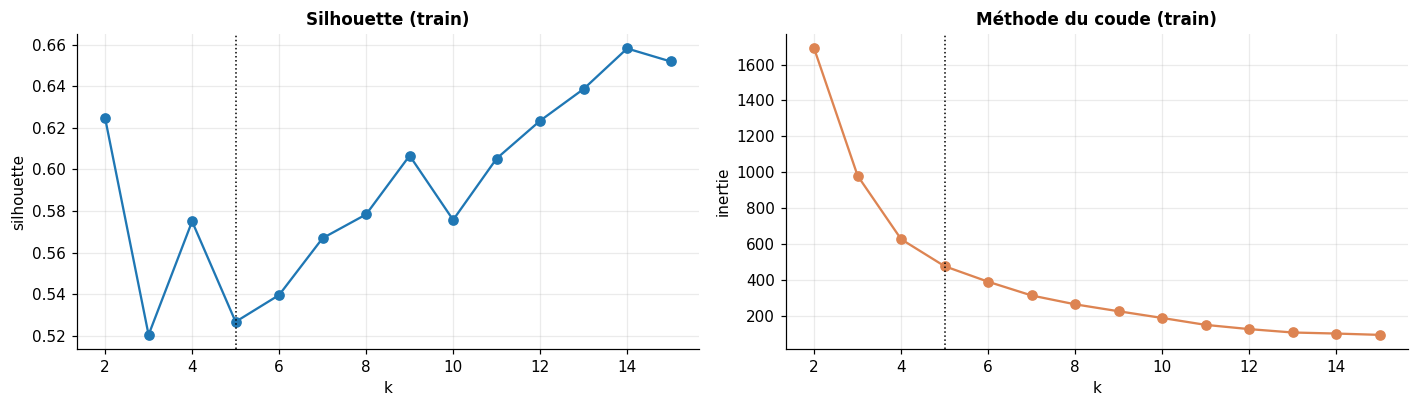

In [26]:
ks = list(range(2, 16))
kms = {k: KMeans(k, n_init=10, random_state=SEED).fit(Z[m_train]) for k in ks}
sil = [silhouette_score(Z[m_train], kms[k].labels_) for k in ks]
inertie = [kms[k].inertia_ for k in ks]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(ks, sil, "o-"); ax[0].set(title="Silhouette (train)", xlabel="k", ylabel="silhouette")
ax[1].plot(ks, inertie, "o-", color="#dd8452"); ax[1].set(title="Méthode du coude (train)", xlabel="k", ylabel="inertie")
for a in ax:
    a.axvline(5, color="k", ls=":", lw=1)
plt.tight_layout(); plt.show()

**Lecture.** Sans correction, la silhouette **augmente presque continuellement jusqu'à $k$ ≈ 14–15**, et la courbe d'inertie n'a pas de coude net à 5. Les données « veulent » plus de 5 groupes : on verra en 7.6 qu'il y en a 15.

### 7.4 Évaluation à K = 5

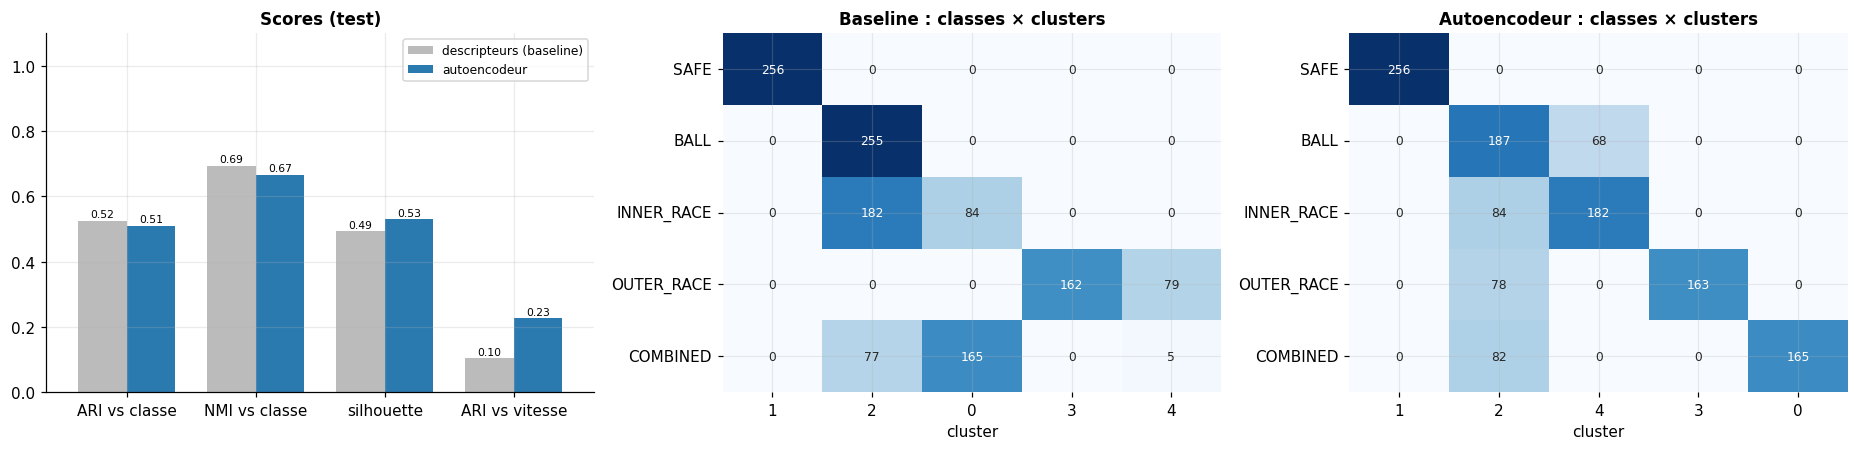

,silhouette,ARI vs classe,NMI vs classe,ARI vs vitesse
méthode,,,,
descripteurs (baseline),0.492,0.525,0.694,0.104
autoencodeur,0.530,0.510,0.666,0.226


In [27]:
K = 5

def evaluer_clustering(nom, donnees):
    km = KMeans(K, n_init=10, random_state=SEED).fit(donnees[m_train])
    clusters = km.predict(donnees[m_test])
    return clusters, {"méthode": nom, **scores_clustering(bd.classe[m_test], clusters, donnees[m_test]),
                      "ARI vs vitesse": adjusted_rand_score(bd.vitesse[m_test], clusters)}

clusters_base, res_base = evaluer_clustering("descripteurs (baseline)", X_clu)
clusters_ae, res_ae = evaluer_clustering("autoencodeur", Z)
res_7 = pd.DataFrame([res_base, res_ae]).set_index("méthode")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
res_7[["ARI vs classe", "NMI vs classe", "silhouette", "ARI vs vitesse"]].T.plot.bar(
    ax=ax[0], rot=0, color=["#bbbbbb", "#2a7ab0"], width=0.75)
etiqueter_barres(ax[0], taille=7); ax[0].set(title="Scores (test)", ylim=(0, 1.1)); ax[0].legend(fontsize=8)
tracer_contingence(ax[1], bd.classe[m_test], clusters_base, "Baseline : classes × clusters")
tracer_contingence(ax[2], bd.classe[m_test], clusters_ae, "Autoencodeur : classes × clusters")
plt.tight_layout(); plt.show()
res_7.round(3)

**Lecture.** Les clusters ne retrouvent qu'**à moitié** les classes (ARI ≈ 0,5). SAFE est parfaitement isolé, mais les défauts sont mélangés. L'autoencodeur fait même **un peu moins bien** que la baseline et dépend **deux fois plus de la vitesse** (ARI vs vitesse 0,23 contre 0,10). Explication : un autoencodeur apprend les sources de variation **dominantes** des données, et sans correction, la vitesse en fait partie. Sa silhouette est pourtant meilleure : des groupes plus nets, mais en partie pour une mauvaise raison.

### 7.5 Visualisation de l'espace latent (t-SNE)
L'espace latent a 6 dimensions. Pour le voir, on le projette en 2D avec **t-SNE**, une méthode qui préserve les voisinages : deux points proches en 6D restent proches en 2D. Les distances entre groupes éloignés et la taille des groupes ne sont pas interprétables.

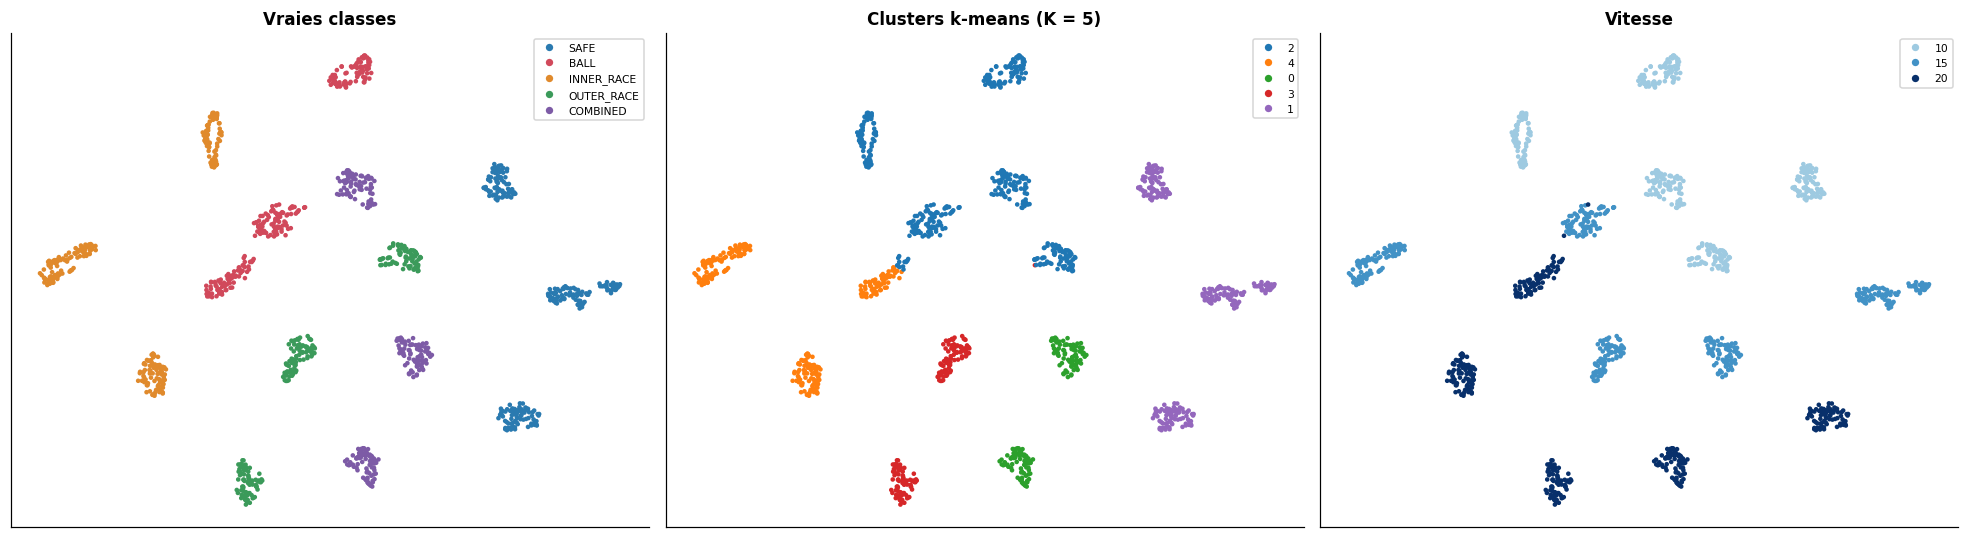

In [28]:
Z_2d = TSNE(n_components=2, random_state=SEED, perplexity=min(30, m_test.sum() - 1)).fit_transform(Z[m_test])

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
tracer_tsne(ax[0], Z_2d, bd.classe[m_test], "Vraies classes", COULEURS, CLASSES)
tracer_tsne(ax[1], Z_2d, clusters_ae.astype(str), "Clusters k-means (K = 5)", "tab10")
tracer_tsne(ax[2], Z_2d, bd.vitesse[m_test].astype(str), "Vitesse", COULEURS_VITESSE, ["10", "15", "20"])
plt.tight_layout(); plt.show()

### 7.6 Hypothèse : 15 groupes classe × vitesse
Le t-SNE montre **15 îlots** : chaque classe est coupée en 3, un îlot par vitesse. Si c'est bien le cas, un k-means à **15 clusters** doit reproduire presque parfaitement les 15 couples (classe, vitesse). On le teste en comparant ces 15 clusters à trois partitions : la classe, la vitesse, et le couple classe × vitesse.

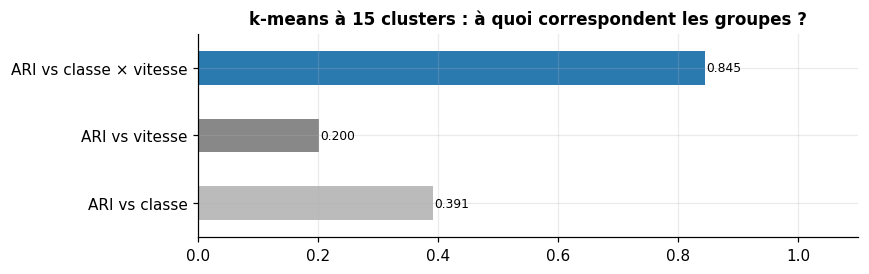

In [29]:
clusters_15 = kms[15].predict(Z[m_test])
couple = (bd.classe + " / " + bd.vitesse.astype(str))[m_test]
test_15 = pd.Series({"ARI vs classe": adjusted_rand_score(bd.classe[m_test], clusters_15),
                     "ARI vs vitesse": adjusted_rand_score(bd.vitesse[m_test], clusters_15),
                     "ARI vs classe × vitesse": adjusted_rand_score(couple, clusters_15)})

ax = test_15.plot.barh(figsize=(8, 2.6), color=["#bbbbbb", "#888888", "#2a7ab0"])
etiqueter_barres(ax, fmt="%.3f")
ax.set(title="k-means à 15 clusters : à quoi correspondent les groupes ?", xlim=(0, 1.1))
plt.tight_layout(); plt.show()

**Lecture.** Si l'ARI vs « classe × vitesse » est proche de 1, l'hypothèse est confirmée : **l'autoencodeur sépare parfaitement les 15 conditions**, mais k-means, à qui l'on demande 5 groupes, doit fusionner des îlots, et il fusionne ceux qui sont proches, c'est-à-dire ceux d'une même vitesse. Le problème ne vient donc ni des descripteurs ni de l'autoencodeur, mais de **la vitesse**. Les deux parties suivantes testent deux façons de la neutraliser.

---
## 8. Stratégie 1 (référence) : un modèle par vitesse

### 8.1 Principe
On traite **chaque vitesse séparément**. Pour chacune : un `StandardScaler`, un autoencodeur et un k-means, tous ajustés sur le **train de cette vitesse**, puis évalués sur le **test de cette vitesse**. La vitesse étant constante dans chaque modèle, elle ne peut plus créer de groupes.

C'est une **référence** : elle donne la performance atteignable quand la vitesse est neutralisée. Limites : 3 modèles au lieu d'un, impossible de traiter une vitesse jamais vue, et des numéros de clusters qui ne se correspondent pas d'une vitesse à l'autre.

In [30]:
ref, lignes = {}, []
for v in sorted(bd.vitesse.unique()):
    m_v = (bd.vitesse == v).to_numpy()
    m_tr, m_te = m_train & m_v, m_test & m_v      # train et test de CETTE vitesse
    classes_te = bd.classe[m_te].to_numpy()

    scaler_v = StandardScaler().fit(bd.loc[m_tr, FEATURES])          # 1. standardisation de cette vitesse
    X_v = scaler_v.transform(bd[FEATURES])
    cl_base = KMeans(K, n_init=10, random_state=SEED).fit(X_v[m_tr]).predict(X_v[m_te])   # 2. baseline

    ae_v = creer_ae((16, 6, 16)).fit(X_v[m_tr], X_v[m_tr])         # 3. AE de cette vitesse, puis k-means
    Z_v = encoder(ae_v, X_v)
    cl_ae = KMeans(K, n_init=10, random_state=SEED).fit(Z_v[m_tr]).predict(Z_v[m_te])

    ref[v] = {"classes_te": classes_te, "cl_base": cl_base, "cl_ae": cl_ae, "Z_te": Z_v[m_te]}
    lignes.append({"vitesse": v, "méthode": "baseline", **scores_clustering(classes_te, cl_base, X_v[m_te])})
    lignes.append({"vitesse": v, "méthode": "autoencodeur", **scores_clustering(classes_te, cl_ae, Z_v[m_te])})

resultats_ref = pd.DataFrame(lignes)
synthese_ref = resultats_ref.groupby("méthode")[["silhouette", "ARI vs classe", "NMI vs classe"]].mean()
resultats_ref.round(3)

,vitesse,méthode,silhouette,ARI vs classe,NMI vs classe
0,10,baseline,0.658,0.952,0.959
1,10,autoencodeur,0.753,1.000,1.000
2,15,baseline,0.675,1.000,1.000
3,15,autoencodeur,0.788,1.000,1.000
4,20,baseline,0.773,1.000,1.000
5,20,autoencodeur,0.806,0.994,0.992


### 8.2 Scores par vitesse
La ligne pointillée rappelle l'ARI de l'autoencodeur sans correction (partie 7).

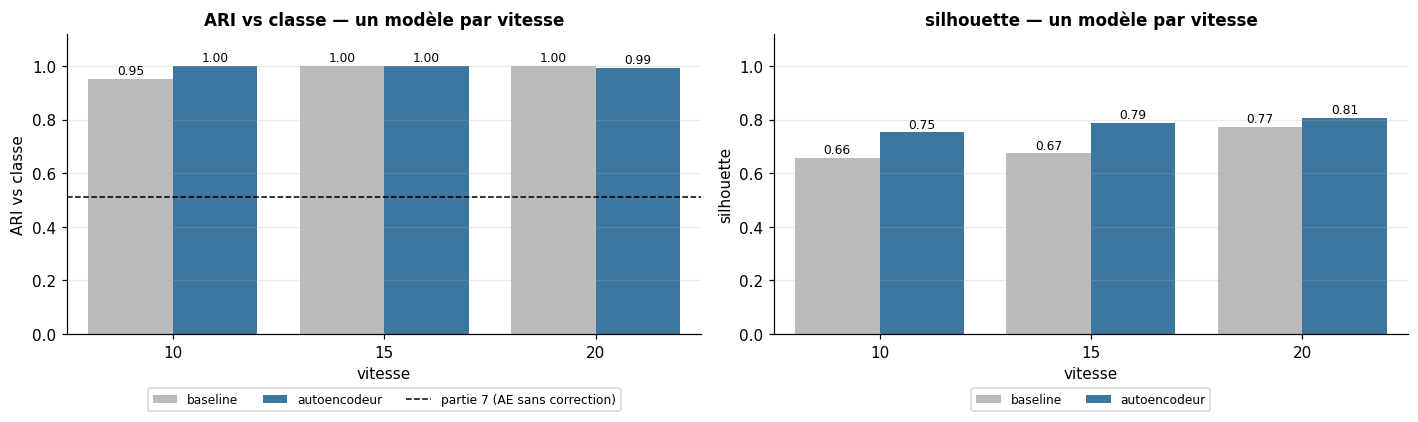

,silhouette,ARI vs classe,NMI vs classe
méthode,,,
autoencodeur,0.782,0.998,0.997
baseline,0.702,0.984,0.986


In [31]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, metrique in zip(ax, ["ARI vs classe", "silhouette"]):
    sns.barplot(data=resultats_ref, x="vitesse", y=metrique, hue="méthode", palette=["#bbbbbb", "#2a7ab0"], ax=a)
    etiqueter_barres(a)
    a.set(ylim=(0, 1.12), title=f"{metrique} — un modèle par vitesse")
ax[0].axhline(res_ae["ARI vs classe"], color="k", ls="--", lw=1, label="partie 7 (AE sans correction)")
for a in ax:
    a.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
plt.tight_layout(); plt.show()
synthese_ref.round(3)

**Lecture.** L'ARI passe d'environ 0,5 à **0,98–1,00** : une fois la vitesse neutralisée, les 5 états se retrouvent presque parfaitement. **La vitesse était bien la cause du problème.** L'autoencodeur fait un peu mieux que la baseline, surtout à la vitesse 10, où les chocs sont les plus faibles et les défauts les plus difficiles à distinguer. Sa silhouette est nettement meilleure : ses groupes sont plus compacts et mieux séparés.

### 8.3 Tables de contingence et espaces latents
En haut, les tables classe × cluster (baseline puis autoencodeur) pour chaque vitesse : une diagonale pleine = clustering parfait. En bas, l'espace latent de chaque modèle (test).

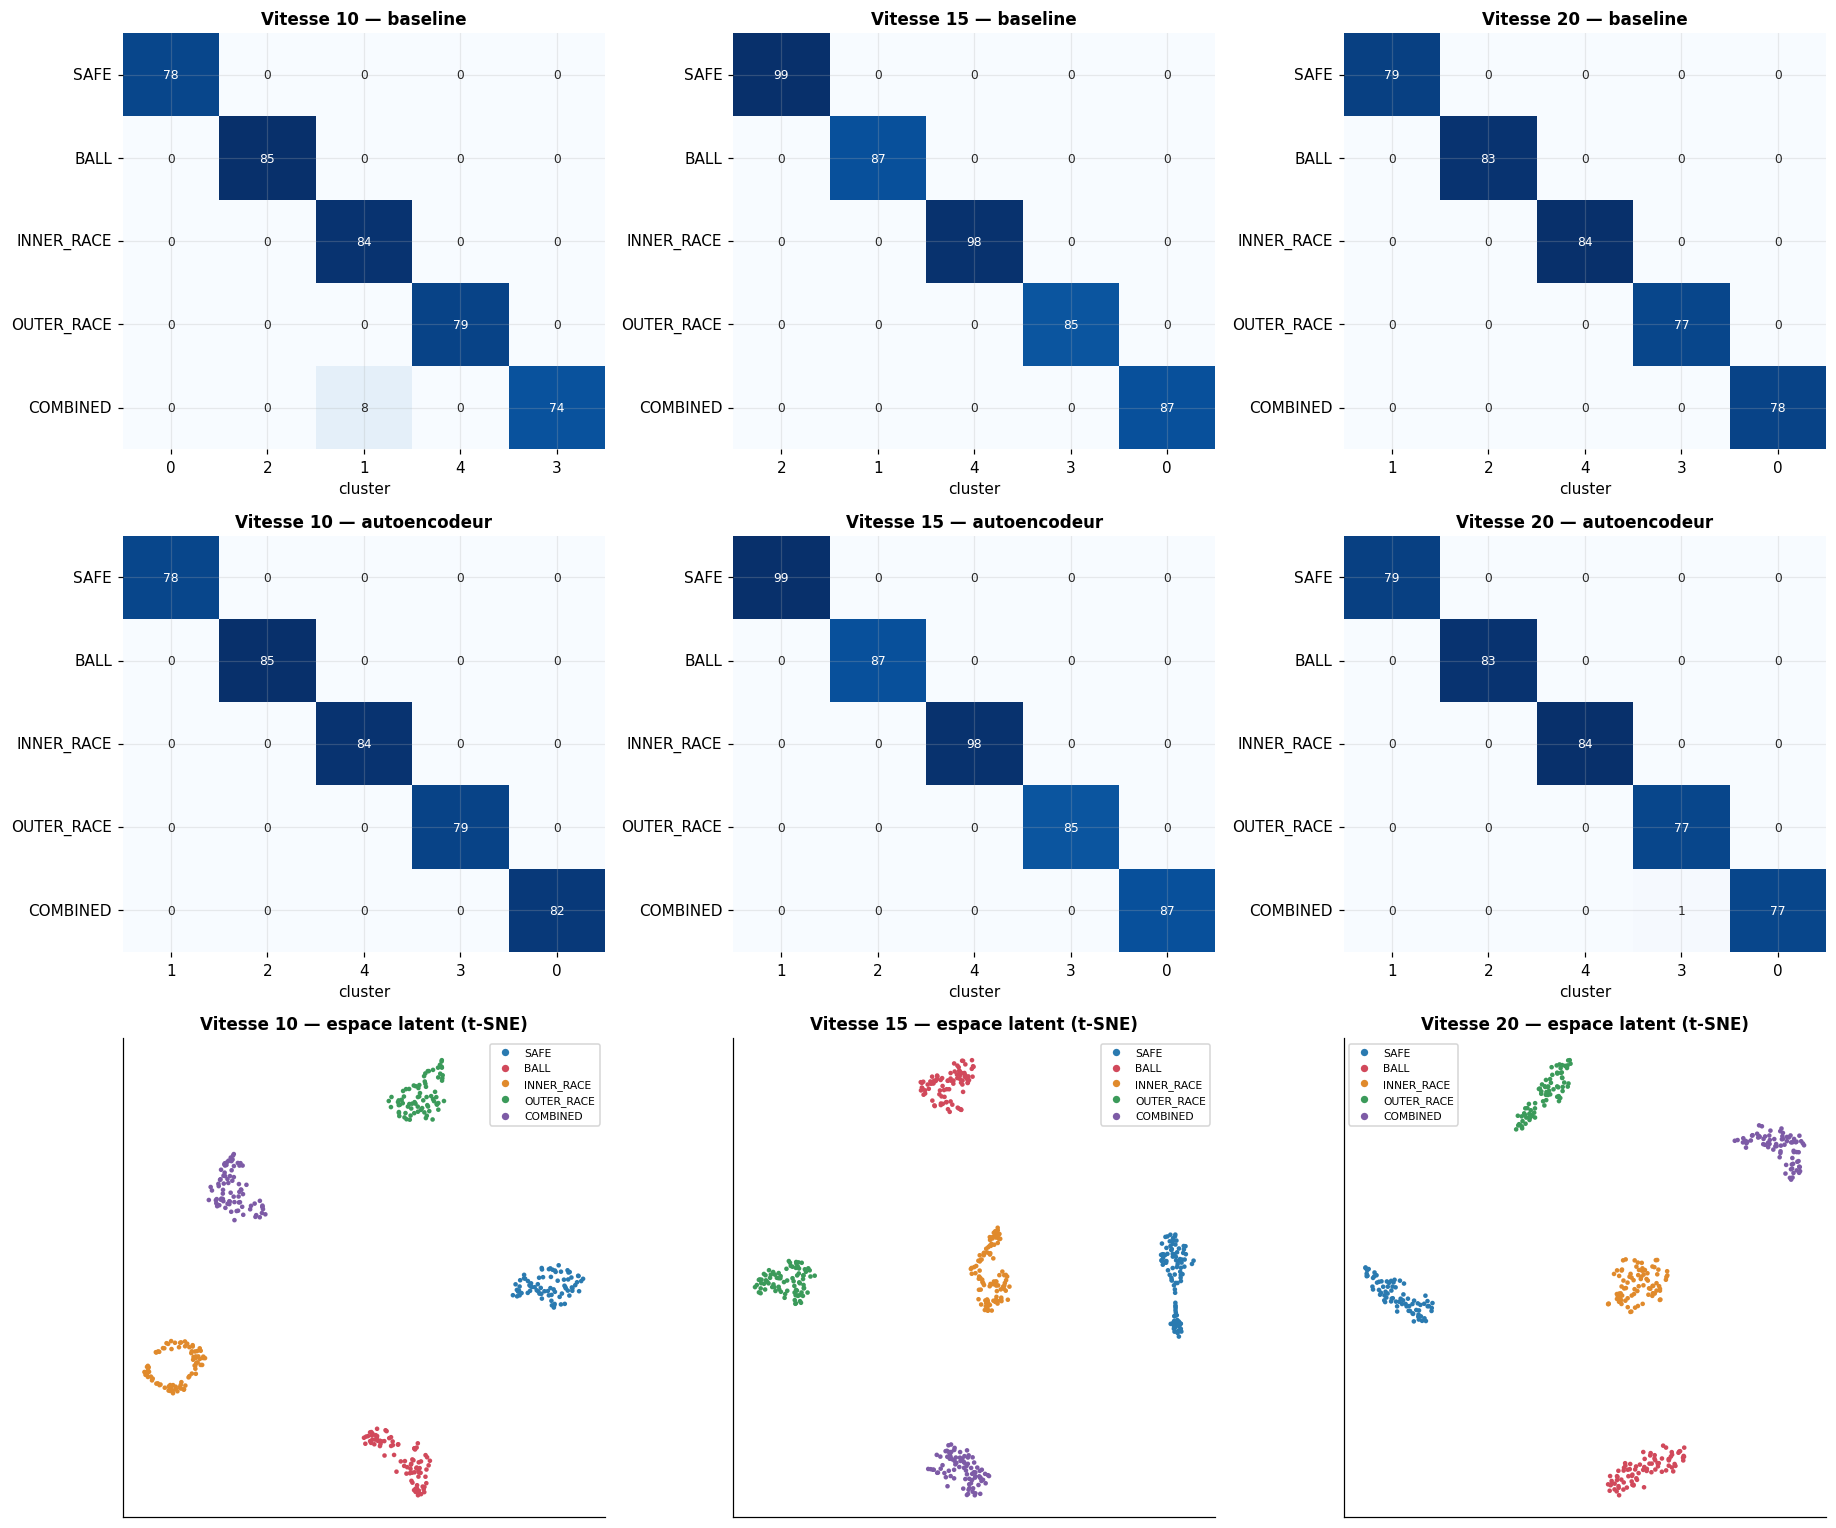

In [32]:
vitesses = sorted(ref)
fig, ax = plt.subplots(3, len(vitesses), figsize=(5.6 * len(vitesses), 14),
                       gridspec_kw={"height_ratios": [1, 1, 1.15]})
for j, v in enumerate(vitesses):
    tracer_contingence(ax[0, j], ref[v]["classes_te"], ref[v]["cl_base"], f"Vitesse {v} — baseline")
    tracer_contingence(ax[1, j], ref[v]["classes_te"], ref[v]["cl_ae"], f"Vitesse {v} — autoencodeur")
    Z_te_2d = TSNE(n_components=2, random_state=SEED, perplexity=min(30, len(ref[v]["Z_te"]) - 1)).fit_transform(ref[v]["Z_te"])
    tracer_tsne(ax[2, j], Z_te_2d, ref[v]["classes_te"], f"Vitesse {v} — espace latent (t-SNE)", COULEURS, CLASSES)
plt.tight_layout(); plt.show()

---
## 9. Stratégie 2 (solution retenue) : log + standardisation par vitesse

### 9.1 Idée
On veut **un seul modèle** pour toutes les vitesses (espace latent commun, clusters comparables), sans que la vitesse structure les données. L'analyse exploratoire (4.3) a montré que la vitesse **multiplie** les niveaux d'énergie. D'où deux étapes :

**Étape 1 : passage au log** de 8 descripteurs (RMS, crête-à-crête, kurtosis et facteur de crête, × 2 capteurs). Les bandes sont déjà en log ; la skewness peut être négative et reste inchangée. Comme $\log(a \times b) = \log a + \log b$, si un descripteur vaut $x = g(v)\,h(c)$ (effet de la vitesse × effet de la classe), alors

$$\log x = \underbrace{\log g(v)}_{\text{décalage dû à la vitesse}} + \underbrace{\log h(c)}_{\text{signature du défaut}}$$

Un effet **multiplicatif** devient un **décalage**. Le log atténue aussi les valeurs extrêmes (une kurtosis de 490 devient 2,7).

**Étape 2 : standardisation séparée pour chaque vitesse.** Pour le signal $i$ de vitesse $v_i$ :

$$z_i = \frac{x_i - \mu_{v_i}}{\sigma_{v_i}}$$

où $\mu_v$ et $\sigma_v$ sont la moyenne et l'écart-type du **train de la vitesse $v$**. Le terme $\log g(v)$, identique pour tous les signaux d'une même vitesse, part avec la moyenne $\mu_v$. Chaque vitesse est ramenée **dans le même repère**.

**Deux conditions nécessaires** : des classes **équilibrées** à chaque vitesse (c'est notre cas, partie 1.1), pour que la moyenne retirée corresponde au même mélange de classes ; et une disposition des classes **semblable** d'une vitesse à l'autre. En pratique, la vitesse doit être connue pour analyser un nouveau signal, ce qui est réaliste (tachymètre, consigne du variateur).

In [33]:
# Étape 1 : passage au log des descripteurs strictement positifs
A_LOGUER = [c for c in FEATURES if c.split("_")[0] in ("rms", "pkpk", "kurtosis", "crete")]
F_log = bd[FEATURES].copy()
F_log[A_LOGUER] = np.log10(F_log[A_LOGUER])
print("Descripteurs passés au log :", A_LOGUER)

# Étape 2 : standardisation séparée pour chaque vitesse (fit sur le train de la vitesse uniquement)
X_norm = np.zeros((len(bd), len(FEATURES)))
scalers_vitesse = {}
for v in sorted(bd.vitesse.unique()):
    m_v = (bd.vitesse == v).to_numpy()
    scalers_vitesse[v] = StandardScaler().fit(F_log[m_train & m_v])
    X_norm[m_v] = scalers_vitesse[v].transform(F_log[m_v])

Descripteurs passés au log : ['rms_vb', 'kurtosis_vb', 'crete_vb', 'pkpk_vb', 'rms_v', 'kurtosis_v', 'crete_v', 'pkpk_v']


### 9.2 La transformation, étape par étape
On suit la **médiane de chaque classe** en fonction de la vitesse, pour deux descripteurs, à chaque étape. Avant : les courbes montent avec la vitesse et se croisent. Après : chaque classe garde à peu près **la même place** quelle que soit la vitesse.

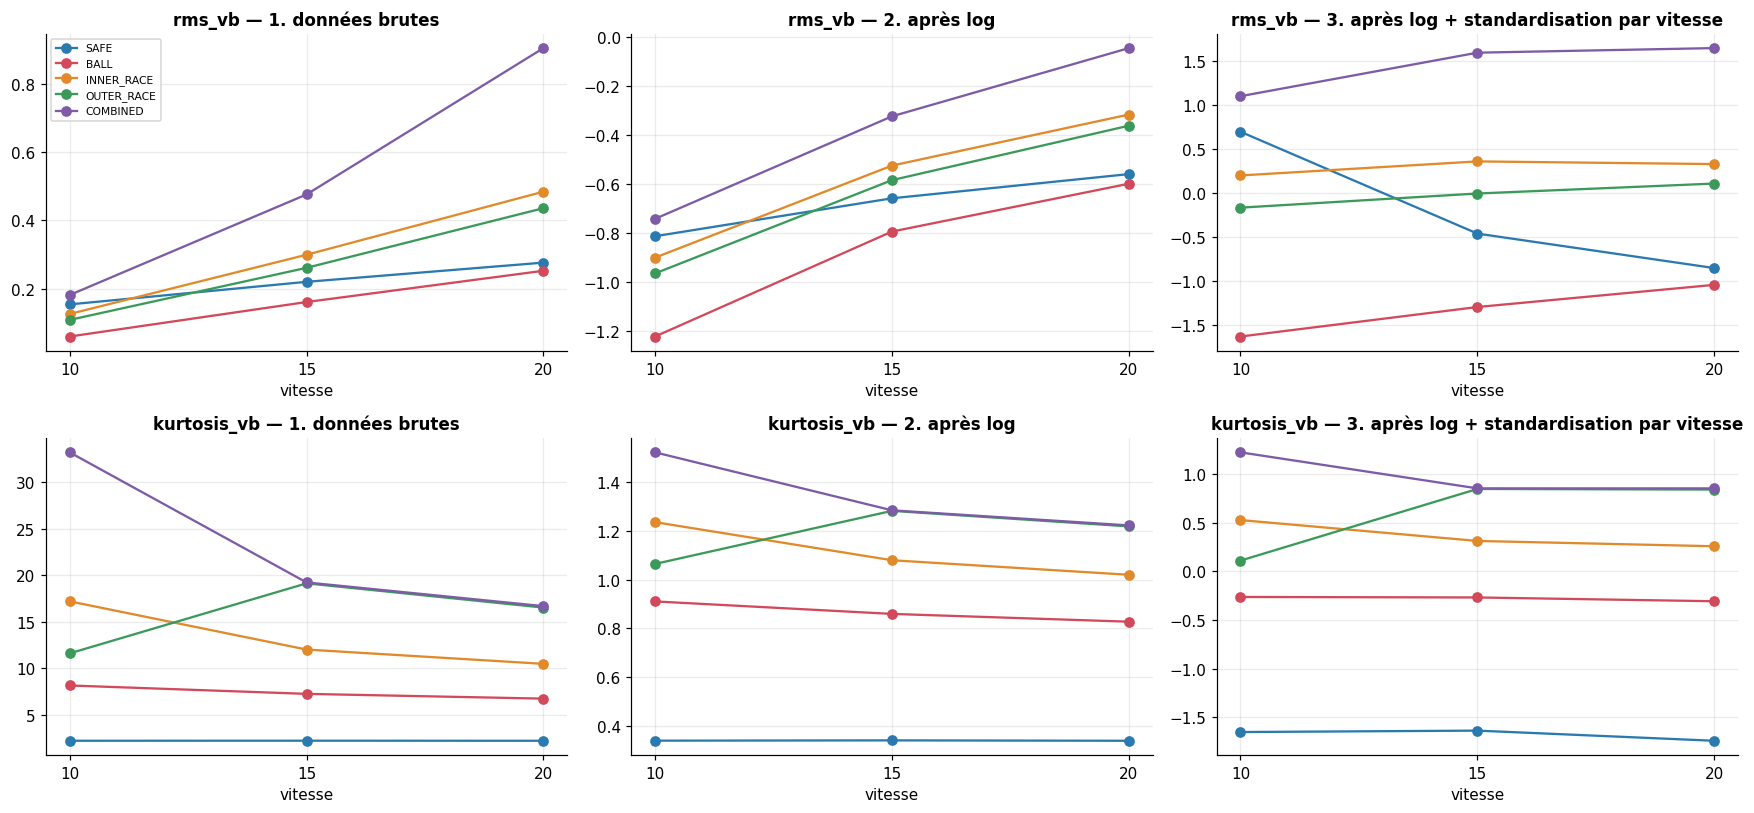

In [34]:
etapes = {"1. données brutes": bd[FEATURES],
          "2. après log": F_log,
          "3. après log + standardisation par vitesse": pd.DataFrame(X_norm, columns=FEATURES, index=bd.index)}
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for i, col in enumerate(["rms_vb", "kurtosis_vb"]):
    for j, (titre, donnees) in enumerate(etapes.items()):
        med = donnees.loc[m_train, col].groupby([bd.classe[m_train], bd.vitesse[m_train]]).median()
        for c in CLASSES:
            ax[i, j].plot([10, 15, 20], med.loc[c].values, "o-", color=COULEURS[c], label=c)
        ax[i, j].set(title=f"{col} — {titre}", xticks=[10, 15, 20], xlabel="vitesse")
ax[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Lecture.** Le log aplatit les écarts relatifs, mais les courbes montent toujours avec la vitesse. Après standardisation par vitesse, les courbes deviennent presque **horizontales** : la vitesse n'a presque plus d'effet, tandis que les classes restent bien séparées. Aucun descripteur ne devient parfaitement indépendant de la vitesse (SAFE varie encore un peu, car son énergie augmente moins vite que celle des défauts), mais le clustering utilise les **26 descripteurs à la fois**.

### 9.3 L'information sur les défauts est-elle conservée ?
On compare le $\eta^2$ **classe** de chaque descripteur avant et après correction. Après correction, le $\eta^2$ vitesse vaut 0 par construction (chaque vitesse est centrée) : l'enjeu est de vérifier que la transformation **n'a pas détruit l'information sur les défauts**.

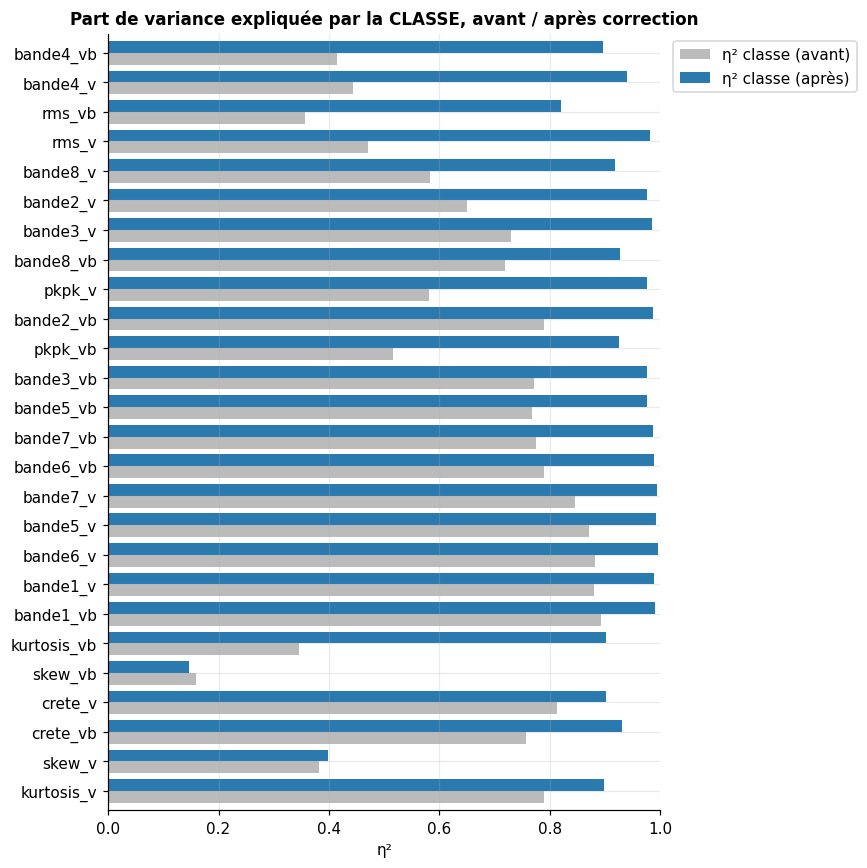

η² vitesse           0.189
η² classe            0.653
η² classe (après)    0.900
dtype: float64

In [35]:
eta = eta_avant.copy()
eta["η² classe (après)"] = [eta2(X_norm[m_train, FEATURES.index(f)], bd.classe[m_train]) for f in eta.index]

ax = eta[["η² classe", "η² classe (après)"]].rename(columns={"η² classe": "η² classe (avant)"}).plot.barh(
    figsize=(8, 8), color=["#bbbbbb", "#2a7ab0"], width=0.8)
ax.set(title="Part de variance expliquée par la CLASSE, avant / après correction", xlim=(0, 1), xlabel="η²")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()
eta.mean().round(3)

**Lecture.** Le $\eta^2$ classe **augmente** pour presque tous les descripteurs (en moyenne de 0,65 à 0,90) : en retirant la variation due à la vitesse, ce qui reste est surtout de la variation due aux défauts. La correction ne détruit pas l'information utile, elle la **révèle**.

### 9.4 Autoencodeur unique et choix de $k$
Même architecture et même démarche qu'en partie 7 : un seul AE, entraîné sur **tout le train** (toutes classes, toutes vitesses, sans étiquette). On superpose les courbes de silhouette et d'inertie de la partie 7 et de la partie 9.

AE entraîné en 188 époques


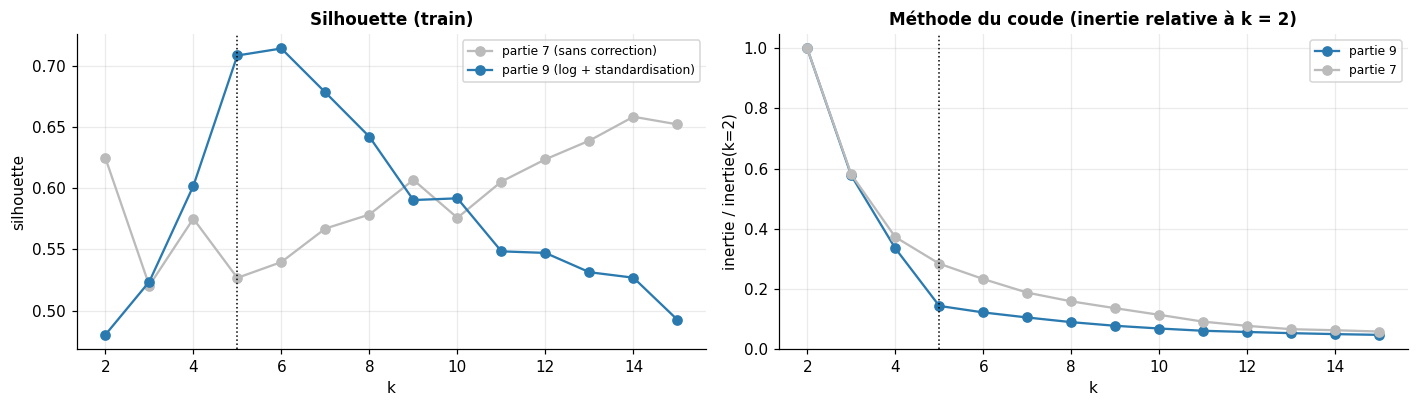

In [36]:
ae_norm = creer_ae((16, 6, 16))
ae_norm.fit(X_norm[m_train], X_norm[m_train])
Z_norm = encoder(ae_norm, X_norm)
print(f"AE entraîné en {ae_norm.n_iter_} époques")

kms_norm = {k: KMeans(k, n_init=10, random_state=SEED).fit(Z_norm[m_train]) for k in ks}
sil_norm = [silhouette_score(Z_norm[m_train], kms_norm[k].labels_) for k in ks]
inertie_norm = [kms_norm[k].inertia_ for k in ks]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(ks, sil, "o-", color="#bbbbbb", label="partie 7 (sans correction)")
ax[0].plot(ks, sil_norm, "o-", color="#2a7ab0", label="partie 9 (log + standardisation)")
ax[0].set(title="Silhouette (train)", xlabel="k", ylabel="silhouette"); ax[0].legend(fontsize=8)
ax[1].plot(ks, np.array(inertie_norm) / inertie_norm[0], "o-", color="#2a7ab0", label="partie 9")
ax[1].plot(ks, np.array(inertie) / inertie[0], "o-", color="#bbbbbb", label="partie 7")
ax[1].set(title="Méthode du coude (inertie relative à k = 2)", xlabel="k", ylabel="inertie / inertie(k=2)")
ax[1].legend(fontsize=8)
for a in ax:
    a.axvline(5, color="k", ls=":", lw=1)
plt.tight_layout(); plt.show()

**Lecture.** Après correction, la silhouette forme un **plateau entre $k$ = 5 et $k$ = 6**, nettement au-dessus du reste, puis chute ; la courbe d'inertie présente un **coude vers $k$ = 5**. Sans utiliser les étiquettes, les données suggèrent maintenant le bon nombre d'états, alors que sans correction elles en suggéraient environ 15.

### 9.5 Hypothèse : pourquoi la silhouette est-elle légèrement meilleure à $k$ = 6 ?
L'écart entre $k$ = 5 et $k$ = 6 est minime. Une explication possible : une classe se coupe en deux sous-groupes. On regarde la partition à 6 clusters du train, ligne par ligne (classe, vitesse) : si une classe se répartit sur deux clusters **selon la vitesse**, c'est un reste de l'effet de la vitesse ; sinon, c'est une hétérogénéité propre à la classe.

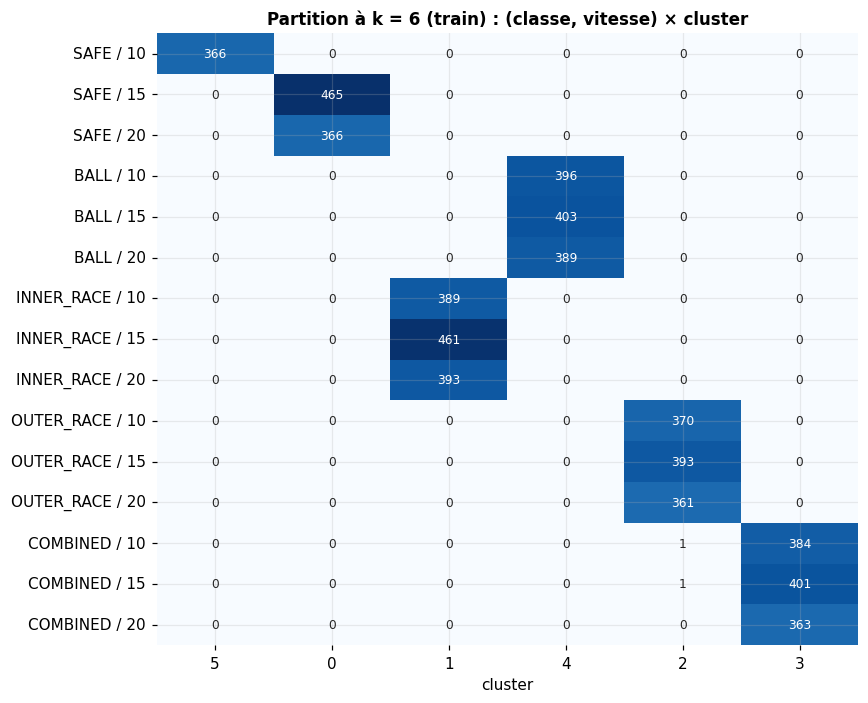

In [37]:
lignes_cv = (bd.classe + " / " + bd.vitesse.astype(str))[m_train].to_numpy()
ordre_cv = [f"{c} / {v}" for c in CLASSES for v in (10, 15, 20)]
fig, ax = plt.subplots(figsize=(8, 6.5))
tracer_contingence(ax, lignes_cv, kms_norm[6].labels_, "Partition à k = 6 (train) : (classe, vitesse) × cluster",
                   ordre_lignes=ordre_cv)
plt.tight_layout(); plt.show()

**Lecture.** Repérez la classe dont les lignes se répartissent sur deux clusters : c'est elle qui fait monter la silhouette à $k$ = 6. On retient **$k$ = 5**, conforme au nombre d'états mécaniques, l'écart de silhouette étant négligeable.

### 9.6 Comparaison avec la partie 7
Même évaluation qu'en partie 7. On attend : **ARI et NMI vs classe en hausse**, **ARI vs vitesse proche de 0**.

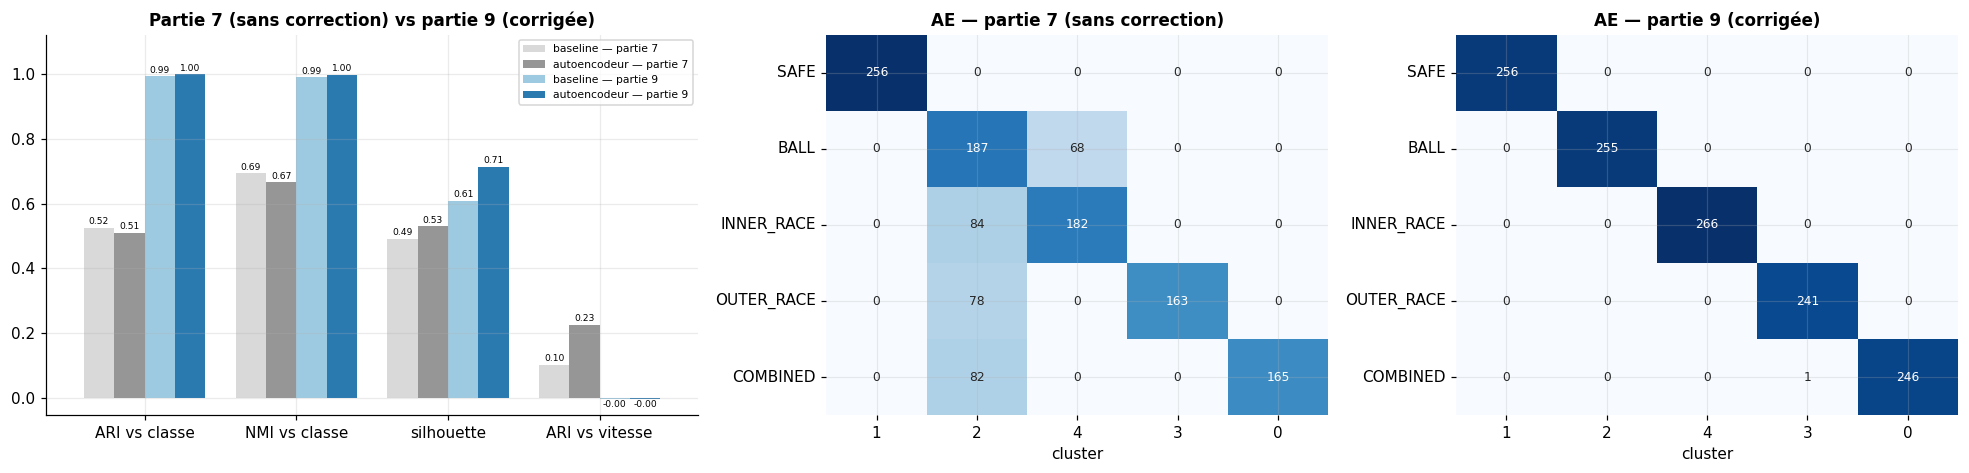

,silhouette,ARI vs classe,NMI vs classe,ARI vs vitesse
méthode,,,,
baseline — partie 7,0.492,0.525,0.694,0.104
autoencodeur — partie 7,0.530,0.510,0.666,0.226
baseline — partie 9,0.608,0.992,0.989,-0.002
autoencodeur — partie 9,0.713,0.998,0.997,-0.002


In [38]:
clusters_base_norm, res_base_norm = evaluer_clustering("baseline — partie 9", X_norm)
clusters_ae_norm, res_ae_norm = evaluer_clustering("autoencodeur — partie 9", Z_norm)
comparaison = pd.DataFrame([{**res_base, "méthode": "baseline — partie 7"},
                            {**res_ae, "méthode": "autoencodeur — partie 7"},
                            res_base_norm, res_ae_norm]).set_index("méthode")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
comparaison[["ARI vs classe", "NMI vs classe", "silhouette", "ARI vs vitesse"]].T.plot.bar(
    ax=ax[0], rot=0, color=["#d9d9d9", "#969696", "#9ecae1", "#2a7ab0"], width=0.8)
etiqueter_barres(ax[0], taille=6)
ax[0].set(title="Partie 7 (sans correction) vs partie 9 (corrigée)", ylim=(min(0, comparaison.values.min()) - 0.05, 1.12))
ax[0].legend(fontsize=7)
tracer_contingence(ax[1], bd.classe[m_test], clusters_ae, "AE — partie 7 (sans correction)")
tracer_contingence(ax[2], bd.classe[m_test], clusters_ae_norm, "AE — partie 9 (corrigée)")
plt.tight_layout(); plt.show()
comparaison.round(3)

### 9.7 Espace latent : avant / après
Ligne du haut : partie 7 ; ligne du bas : partie 9. Si la correction fonctionne, les 3 îlots d'une même classe se superposent (à gauche) et les couleurs de vitesse se mélangent à l'intérieur de chaque groupe (à droite).

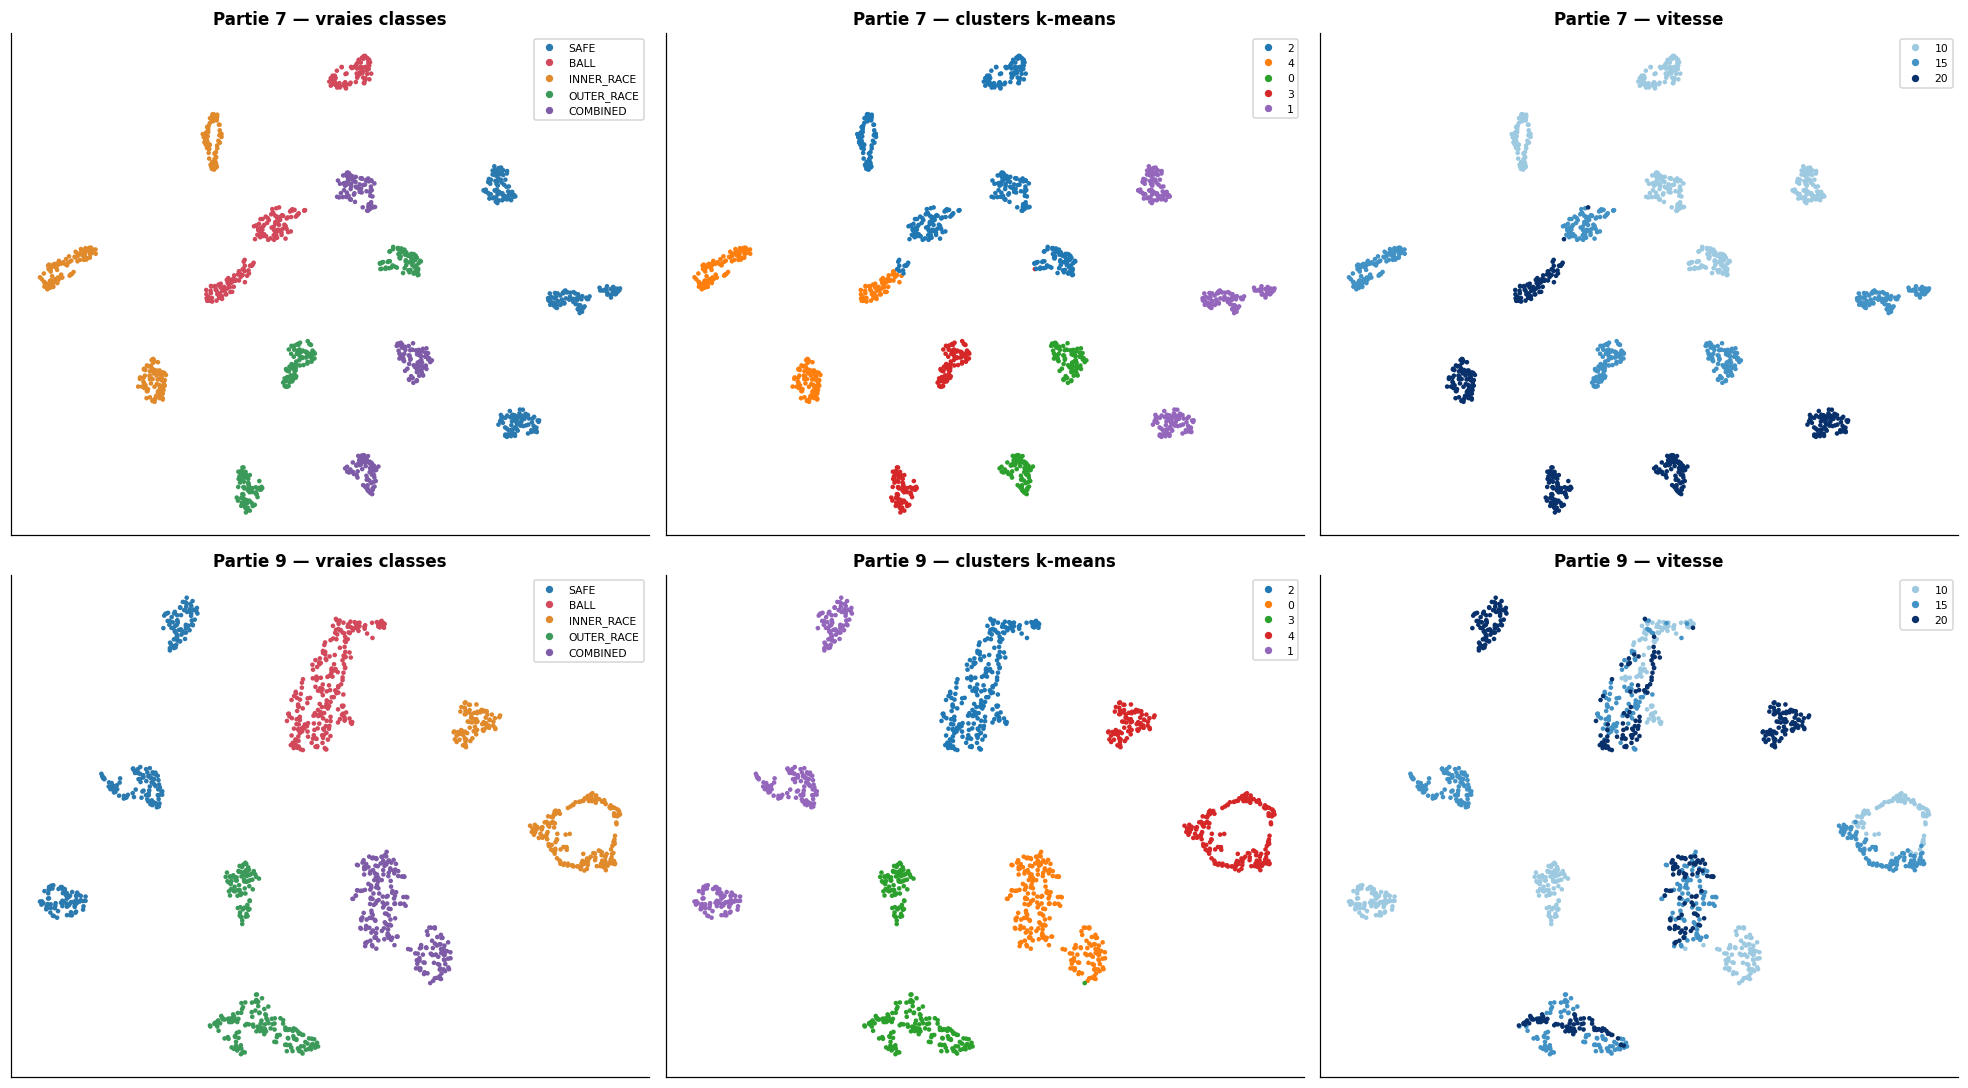

In [39]:
Z_norm_2d = TSNE(n_components=2, random_state=SEED, perplexity=min(30, m_test.sum() - 1)).fit_transform(Z_norm[m_test])

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
for i, (Z2, cl, nom) in enumerate([(Z_2d, clusters_ae, "Partie 7"), (Z_norm_2d, clusters_ae_norm, "Partie 9")]):
    tracer_tsne(ax[i, 0], Z2, bd.classe[m_test], f"{nom} — vraies classes", COULEURS, CLASSES)
    tracer_tsne(ax[i, 1], Z2, cl.astype(str), f"{nom} — clusters k-means", "tab10")
    tracer_tsne(ax[i, 2], Z2, bd.vitesse[m_test].astype(str), f"{nom} — vitesse", COULEURS_VITESSE, ["10", "15", "20"])
plt.tight_layout(); plt.show()

**Lecture.** Après correction, les **15 îlots deviennent 5 groupes**, chacun correspondant à une classe, et les vitesses sont mélangées à l'intérieur de chaque groupe. Les clusters k-means coïncident presque exactement avec les vraies classes.

---
## 10. Bilan

### 10.1 Les trois approches de clustering
Chaque approche est évaluée avec sa baseline (k-means sur les descripteurs) et son autoencodeur. L'ARI vs vitesse n'a pas de sens pour la stratégie 1 (chaque modèle ne voit qu'une vitesse).

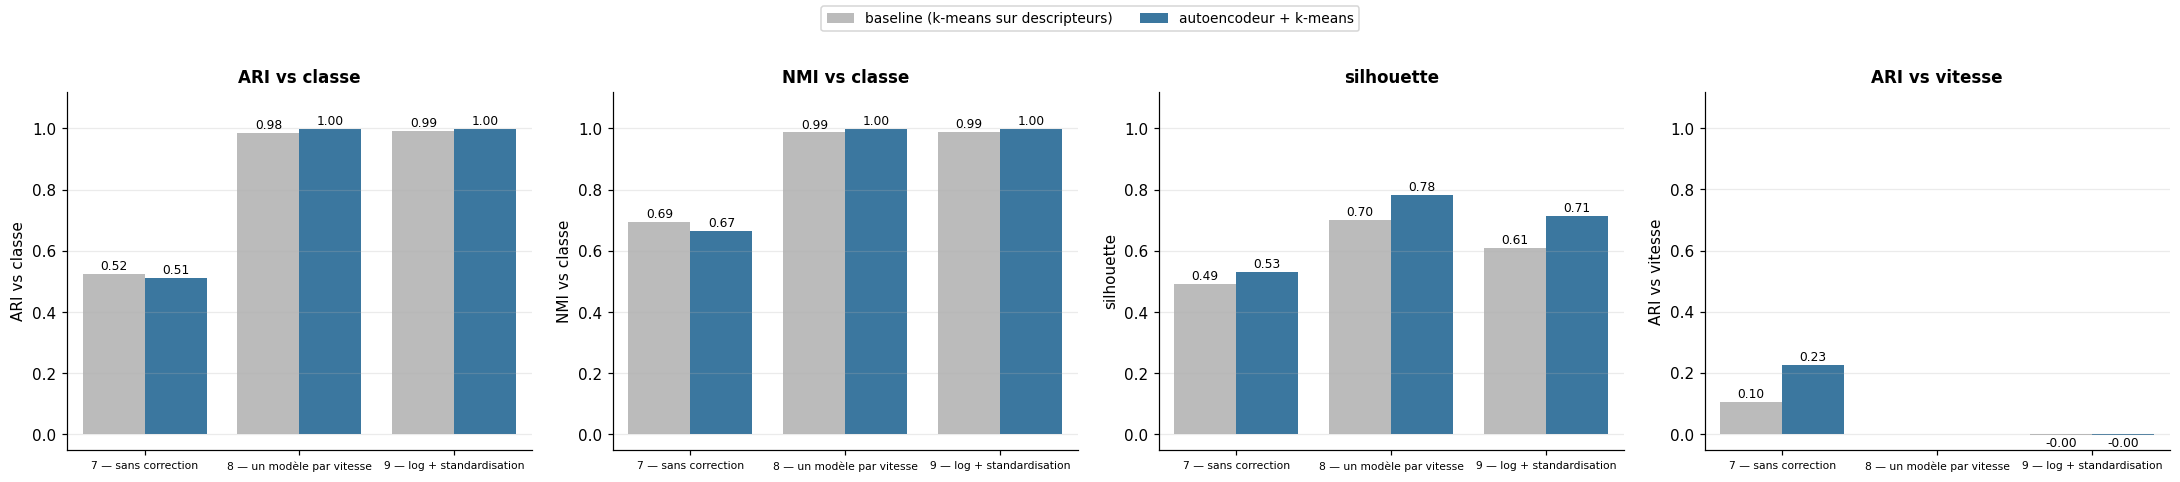

,approche,modèle,ARI vs classe,NMI vs classe,silhouette,ARI vs vitesse
0,7 — sans correction,baseline (k-means sur descripteurs),0.525,0.694,0.492,0.104
1,7 — sans correction,autoencodeur + k-means,0.510,0.666,0.530,0.226
2,8 — un modèle par vitesse,baseline (k-means sur descripteurs),0.984,0.986,0.702,NaN
3,8 — un modèle par vitesse,autoencodeur + k-means,0.998,0.997,0.782,NaN
4,9 — log + standardisation,baseline (k-means sur descripteurs),0.992,0.989,0.608,-0.002
5,9 — log + standardisation,autoencodeur + k-means,0.998,0.997,0.713,-0.002


In [40]:
lignes_bilan = []
for approche, base, ae_res in [("7 — sans correction", res_base, res_ae),
                               ("8 — un modèle par vitesse",
                                synthese_ref.loc["baseline"].to_dict(), synthese_ref.loc["autoencodeur"].to_dict()),
                               ("9 — log + standardisation", res_base_norm, res_ae_norm)]:
    for modele_nom, r in [("baseline (k-means sur descripteurs)", base), ("autoencodeur + k-means", ae_res)]:
        lignes_bilan.append({"approche": approche, "modèle": modele_nom,
                             "ARI vs classe": r["ARI vs classe"], "NMI vs classe": r["NMI vs classe"],
                             "silhouette": r["silhouette"], "ARI vs vitesse": r.get("ARI vs vitesse", np.nan)})
bilan = pd.DataFrame(lignes_bilan)

fig, ax = plt.subplots(1, 4, figsize=(20, 4.4))
for a, metrique in zip(ax, ["ARI vs classe", "NMI vs classe", "silhouette", "ARI vs vitesse"]):
    sns.barplot(data=bilan, x="approche", y=metrique, hue="modèle", palette=["#bbbbbb", "#2a7ab0"], ax=a)
    etiqueter_barres(a)
    a.set(xlabel="", title=metrique, ylim=(min(0, bilan[metrique].min()) - 0.05, 1.12))
    a.tick_params(axis="x", labelsize=7)
    a.get_legend().remove()
fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", ncol=2, fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()
bilan.round(3)

### 10.2 Conclusions

**Détection d'anomalie.** Tous les modèles détectent 100 % des défauts (AUROC = 1), avec 1 à 2 % de fausses alarmes. Sur ces données, la détection est une tâche facile : une simple Isolation Forest ou une ACP suffisent. L'autoencodeur se distingue par son **interprétabilité** : la décomposition de son erreur montre quels descripteurs trahissent chaque défaut.

**Clustering.**
1. **Sans correction**, le clustering est dominé par la vitesse (ARI ≈ 0,5), et l'autoencodeur amplifie ce biais en encodant en priorité cette source de variance dominante.
2. **Un modèle par vitesse** confirme le diagnostic : l'ARI monte à 0,98–1,00.
3. **Le passage au log suivi d'une standardisation par vitesse** supprime le biais (ARI vs vitesse ≈ 0) et permet à **un seul modèle** d'égaler la référence (ARI ≈ 1,00).
4. **L'essentiel du gain vient du prétraitement** : la baseline passe elle aussi d'environ 0,5 à 0,99. L'autoencodeur apporte surtout une **meilleure séparation des groupes** (silhouette plus élevée), donc une marge plus confortable pour classer de nouveaux signaux.

**Limites.**
- **Scores optimistes** : chaque couple (classe, vitesse) est une série d'acquisitions consécutives, et le découpage aléatoire place des signaux presque identiques dans le train et le test. Le test décisif serait une évaluation sur une vitesse jamais vue.
- **Un scaler par vitesse connue** : pour une nouvelle vitesse, il faudrait interpoler $\mu_v$ et $\sigma_v$ ou recalibrer avec quelques signaux de cette vitesse.
- **Une seule graine** et **$K$ = 5 fixé** grâce à notre connaissance des classes : des écarts de l'ordre de 0,01 ne doivent pas être interprétés.

**Pistes.** Évaluation sur vitesse inconnue ; descripteurs d'enveloppe et fréquences caractéristiques des défauts (BPFO, BPFI, BSF) ; autoencodeur convolutif sur le signal brut ; VAE ou DEC pour un espace latent mieux structuré.

---
## 11. Sauvegarde du modèle retenu

### 11.1 Ce que l'on sauvegarde, et pourquoi
Le modèle retenu combine les deux usages de l'autoencodeur :

| Usage | Modèle retenu | Justification |
|---|---|---|
| **Détection** : ce roulement est-il défectueux ? | AE sur les 26 descripteurs, seuil au 99ᵉ percentile des SAFE de validation | 100 % des défauts détectés ; erreur interprétable par descripteur |
| **Diagnostic** : quel type de défaut ? | log + standardisation par vitesse, AE unique, k-means à 5 clusters | un seul modèle pour les 3 vitesses ; ARI ≈ 1 ; meilleure séparation que la baseline |

Les clusters de k-means sont des numéros (0 à 4). Pour que l'application affiche un nom d'état, on associe à chaque cluster la **classe majoritaire de ses signaux d'entraînement**. Les étiquettes servent seulement à **nommer** les groupes, pas à les construire.

Tout est rangé dans **un seul fichier** (`joblib`), avec la version de scikit-learn utilisée : un modèle doit être rechargé avec la même version.

In [41]:
km_final = KMeans(K, n_init=10, random_state=SEED).fit(Z_norm[m_train])

# Nom de chaque cluster = classe majoritaire de ses signaux d'entraînement
tab_noms = pd.crosstab(km_final.labels_, bd.classe[m_train].to_numpy())
nom_cluster = tab_noms.idxmax(axis=1).to_dict()
print("Correspondance cluster -> état :", nom_cluster)
if len(set(nom_cluster.values())) < K:
    print("⚠️ Deux clusters portent le même nom : vérifier la table de contingence.")

modele_final = {
    "description": "Diagnostic de roulements par autoencodeurs : détection d'anomalie + identification de l'état",
    "date": str(date.today()),
    "version_sklearn": sklearn.__version__,
    "features": FEATURES,
    "detection": {"scaler": scaler, "autoencodeur": ae, "seuil": float(seuil_ae)},
    "diagnostic": {"a_loguer": A_LOGUER, "scalers_vitesse": scalers_vitesse,
                   "autoencodeur": ae_norm, "kmeans": km_final, "nom_cluster": nom_cluster},
    "performances_test": {
        "detection": resultats_det.loc["AE (descripteurs)", ["AUROC", "rappel", "fausses alarmes"]].round(4).to_dict(),
        "diagnostic": {k: round(float(v), 4) for k, v in res_ae_norm.items() if k != "méthode"},
    },
}
FICHIER_MODELE = Path("modele_final_roulements.joblib")
joblib.dump(modele_final, FICHIER_MODELE)
print(f"Modèle sauvegardé dans {FICHIER_MODELE} ({FICHIER_MODELE.stat().st_size / 1024:.0f} Ko)")

Correspondance cluster -> état : {0: 'COMBINED', 1: 'SAFE', 2: 'BALL', 3: 'OUTER_RACE', 4: 'INNER_RACE'}
Modèle sauvegardé dans modele_final_roulements.joblib (97 Ko)


### 11.2 Utiliser le modèle : la fonction `analyser`
Cette fonction est celle que l'application appellera. Elle prend les **26 descripteurs** d'un ou plusieurs signaux (calculés avec `extraire`) et leur **vitesse**, et renvoie pour chacun :
- `score_anomalie` et `alarme` (détection) ;
- `cluster` et `etat_estime` (diagnostic).

Elle refuse une vitesse pour laquelle aucun scaler n'a été appris, plutôt que de donner un résultat faux.

In [ ]:
def analyser(modele, descripteurs, vitesses):
    D = descripteurs[modele["features"]]
    vitesses = np.asarray(vitesses)

    # 1. Détection : erreur de reconstruction de l'AE entraîné sur les signaux sains
    det = modele["detection"]
    Xd = det["scaler"].transform(D)
    score = np.mean((Xd - det["autoencodeur"].predict(Xd)) ** 2, axis=1)

    # 2. Diagnostic : log, standardisation de la vitesse du signal, encodage, k-means
    diag = modele["diagnostic"]
    inconnues = set(np.unique(vitesses)) - set(diag["scalers_vitesse"])
    if inconnues:
        raise ValueError(f"Vitesse(s) {sorted(inconnues)} inconnue(s) : le modèle connaît {sorted(diag['scalers_vitesse'])}")
    F = D.copy()
    F[diag["a_loguer"]] = np.log10(F[diag["a_loguer"]])
    Xc = np.zeros(F.shape)
    for v, sc in diag["scalers_vitesse"].items():
        m = vitesses == v
        if m.any():
            Xc[m] = sc.transform(F[m])
    clusters = diag["kmeans"].predict(encoder(diag["autoencodeur"], Xc))

    return pd.DataFrame({"score_anomalie": score, "alarme": score > det["seuil"], "cluster": clusters,
                         "etat_estime": [diag["nom_cluster"][c] for c in clusters]}, index=descripteurs.index)

### 11.3 Vérification : recharger le modèle et l'appliquer au jeu de test
On recharge le fichier depuis le disque, comme le fera l'application, et on vérifie que :
1. les prédictions sont **identiques** à celles du notebook ;
2. l'état estimé correspond bien à la vraie classe (matrice de confusion).

In [ ]:
modele_recharge = joblib.load(FICHIER_MODELE)
resultat = analyser(modele_recharge, bd.loc[m_test, FEATURES], bd.vitesse[m_test])

identiques_det = np.array_equal(resultat.alarme.to_numpy(), score_ae[m_test] > seuil_ae)
identiques_diag = np.array_equal(resultat.cluster.to_numpy(), km_final.predict(Z_norm[m_test]))
exactitude = (resultat.etat_estime == bd.classe[m_test]).mean()
print(f"Détection identique au notebook : {identiques_det}")
print(f"Diagnostic identique au notebook : {identiques_diag}")
print(f"État correctement identifié : {exactitude:.1%} des signaux de test")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
mat = pd.crosstab(bd.classe[m_test], resultat.etat_estime).reindex(index=CLASSES, columns=CLASSES).fillna(0).astype(int)
sns.heatmap(mat, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0])
ax[0].set(title="Vraie classe × état estimé par le modèle sauvegardé (test)", xlabel="état estimé", ylabel="vraie classe")
alarmes = resultat.groupby(bd.classe[m_test]).alarme.mean().loc[CLASSES]
alarmes.plot.bar(ax=ax[1], color=[COULEURS[c] for c in CLASSES], rot=20)
etiqueter_barres(ax[1], fmt="%.3f")
ax[1].set(title="Taux d'alarme par classe (test)", ylim=(0, 1.12), xlabel="")
plt.tight_layout(); plt.show()

resultat.assign(vraie_classe=bd.classe[m_test].to_numpy(), vitesse=bd.vitesse[m_test].to_numpy()).head(8)

### 11.4 Réutiliser le modèle dans l'application
L'application (Streamlit, par exemple) a besoin de trois fonctions de ce notebook, à recopier telles quelles : `lire_signal` (avec `normaliser` et `lire_textes`), `extraire` et `encoder`, plus `analyser`. Le principe :

```python
modele = joblib.load("modele_final_roulements.joblib")
desc, _ = extraire("nouveau_signal.xlsx")                 # 26 descripteurs
resultat = analyser(modele, pd.DataFrame([desc]), [15])    # vitesse de la machine
```

Le fichier doit être rechargé avec la **même version de scikit-learn** que celle enregistrée dans `modele["version_sklearn"]`.